# BIL545 · Güncel Bölüm 3

**Hazırlayan:** Kerem Can Atlıhan · **Kapsam:** 4.3 Veri küpü ve birliktelik analizi


In [ ]:

import os, shutil, sys, subprocess, importlib.metadata
# Paketler import edilmeden önce doğrulanmış sürümler hazırlanır.
gerekli={"numpy":"2.4.6","pandas":"2.2.3","scipy":"1.16.3","scikit-learn":"1.6.1","matplotlib":"3.10.0","mlxtend":"0.23.4"}
eksik=[]
for paket,surum in gerekli.items():
    try: uygun=importlib.metadata.version(paket)==surum
    except importlib.metadata.PackageNotFoundError: uygun=False
    if not uygun: eksik.append(paket+"=="+surum)
if eksik: subprocess.check_call([sys.executable,"-m","pip","install",*eksik])
try:
    import certifi
    os.environ["SSL_CERT_FILE"]=certifi.where()
except ImportError: pass
os.environ["JAVA_TOOL_OPTIONS"]=(os.environ.get("JAVA_TOOL_OPTIONS","")+" -Duser.language=en -Duser.country=US").strip()
from pathlib import Path
from IPython.display import display, Markdown
JAVA=shutil.which("java")
yerel_java=Path("/Applications/weka-3.8.7.app/Contents/runtime/Contents/Home/bin/java")
if yerel_java.exists(): JAVA=str(yerel_java)
if JAVA is None: raise RuntimeError("Java 17+ gerekli.")
Path("uretilen").mkdir(exist_ok=True)

veri_csv=Path("bank-full.csv")
if not veri_csv.exists():
    try:
        import io, zipfile, urllib.request
        with urllib.request.urlopen("https://archive.ics.uci.edu/static/public/222/bank+marketing.zip",timeout=120) as yanit:
            dis_zip=zipfile.ZipFile(io.BytesIO(yanit.read()))
        ic_ad=[a for a in dis_zip.namelist() if a.endswith("bank.zip")][0]
        ic_zip=zipfile.ZipFile(io.BytesIO(dis_zip.read(ic_ad)))
        csv_ad=[a for a in ic_zip.namelist() if a.endswith("bank-full.csv")][0]
        veri_csv.write_bytes(ic_zip.read(csv_ad))
        print("bank-full.csv UCI deposundan indirildi:",veri_csv.resolve())
    except Exception as hata:
        print("Otomatik indirme yapılamadı; bank-full.csv dosyasını elle yükleyin. Ayrıntı:",hata)


bank-full.csv UCI deposundan indirildi: /content/bank-full.csv


In [2]:
import sys
import random
import numpy as np
import pandas as pd
import sklearn
import scipy

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("Random seed:", SEED)

Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
SciPy: 1.16.3
Random seed: 42


In [3]:
from pathlib import Path


# Veri dosyasının konumu
dosya_yolu = Path("bank-full.csv")

# Dosya bulunmuyorsa kullanıcıdan yüklemesini iste
if not dosya_yolu.exists():
    print("Lütfen bank-full.csv dosyasını yükleyin.")
    try:
        from google.colab import files
        files.upload()
    except ImportError as exc:
        raise FileNotFoundError("bank-full.csv dosyasini notebook ile ayni klasore koyun.") from exc

# Dosyanın varlığını kontrol et
if not dosya_yolu.exists():
    raise FileNotFoundError("bank-full.csv bulunamadı.")

# Veri kümesini oku
df = pd.read_csv(dosya_yolu, sep=";")

# Temel bilgileri göster
print("Satır sayısı:", df.shape[0])
print("Sütun sayısı:", df.shape[1])
print("Sütunlar:", df.columns.tolist())

display(df.head())

Satır sayısı: 45211
Sütun sayısı: 17
Sütunlar: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
from pathlib import Path
import hashlib
import pandas as pd

# İlk veri yükleme hücresinde kullanılan dosya
ham_dosya = dosya_yolu

assert ham_dosya.is_file(), (
    "bank-full.csv bulunamadı. "
    "Önce veri dosyasını Colab'a yükleyin."
)

# Ham veri üzerinde bağımsız bütünlük kontrolü
ham_kontrol = pd.read_csv(ham_dosya, sep=";")

beklenen_sutunlar = [
    "age", "job", "marital", "education",
    "default", "balance", "housing", "loan",
    "contact", "day", "month", "duration",
    "campaign", "pdays", "previous",
    "poutcome", "y"
]

assert ham_kontrol.shape == (45211, 17)
assert ham_kontrol.columns.tolist() == beklenen_sutunlar
assert (ham_kontrol["y"] == "yes").sum() == 5289

with open(ham_dosya, "rb") as f:
    veri_hash = hashlib.file_digest(
        f, "sha256"
    ).hexdigest()

print("=== HAM VERİ BÜTÜNLÜK KONTROLÜ ===")
print("Dosya:", ham_dosya.name)
print("Boyut:", ham_kontrol.shape)
print(
    "Pozitif hedef sayısı:",
    (ham_kontrol["y"] == "yes").sum()
)
print("SHA-256:", veri_hash)

print("\nHam veri bütünlük kontrolü başarılı.")

beklenen_veri_hash = (
    "d1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa264b3aaf0f849ed32d"
)

assert veri_hash == beklenen_veri_hash, (
    "Ham veri dosyasının SHA-256 değeri beklenen değerle eşleşmiyor."
)

print("Ham veri SHA-256 doğrulaması başarılı.")

=== HAM VERİ BÜTÜNLÜK KONTROLÜ ===
Dosya: bank-full.csv
Boyut: (45211, 17)
Pozitif hedef sayısı: 5289
SHA-256: d1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa264b3aaf0f849ed32d

Ham veri bütünlük kontrolü başarılı.
Ham veri SHA-256 doğrulaması başarılı.


In [5]:
# Orijinal veri kümesini koru
df_eksiklik = df.copy()

# Bilinmeyen kategorik değerler
eksik_sutunlar = ["job", "education", "contact"]

for sutun in eksik_sutunlar:
    df_eksiklik[sutun] = df_eksiklik[sutun].replace(
        "unknown", np.nan
    )

# Önceki iletişim gerçekleşmemişse
# önceki kampanya sonucu uygulanabilir değildir
iletisim_yok = df["previous"] == 0

df_eksiklik.loc[
    iletisim_yok, "poutcome"
] = "not_applicable"

# Önceki iletişim var fakat sonuç bilinmiyorsa
# eksik değer olarak işaretle
sonuc_bilinmiyor = (
    (df["previous"] > 0) &
    (df["poutcome"] == "unknown")
)

df_eksiklik.loc[
    sonuc_bilinmiyor, "poutcome"
] = np.nan

# Eksik değerlerin özetini oluştur
eksiklik_ozeti = pd.DataFrame({
    "Eksik sayısı": df_eksiklik.isna().sum(),
    "Eksik oranı (%)": (
        df_eksiklik.isna().mean() * 100
    )
})

eksiklik_ozeti = eksiklik_ozeti.sort_values(
    "Eksik oranı (%)", ascending=False
)

display(eksiklik_ozeti.round(2))

# Orijinal verinin değişmediğini kontrol et
assert df.isna().sum().sum() == 0

print("Orijinal veri korunmuştur.")

,Eksik sayısı,Eksik oranı (%)
contact,13020,28.80
education,1857,4.11
job,288,0.64
poutcome,5,0.01
age,0,0.00
default,0,0.00
balance,0,0.00
housing,0,0.00
marital,0,0.00
loan,0,0.00


Orijinal veri korunmuştur.


In [6]:
# Modelleme verisini oluştur
X = df_eksiklik.drop(columns=["y", "duration"])

# Hedef değişkeni ikili hale getir
y = (df_eksiklik["y"] == "yes").astype(int)

# İlk %80 geliştirme, son %20 ileri dönem testi
ayrim = int(len(X) * 0.80)

X_gelistirme = X.iloc[:ayrim].copy()
X_test = X.iloc[ayrim:].copy()

y_gelistirme = y.iloc[:ayrim].copy()
y_test = y.iloc[ayrim:].copy()

# Veri boyutlarını göster
print("Geliştirme verisi:", X_gelistirme.shape)
print("Test verisi:", X_test.shape)

# Pozitif sınıf oranlarını incele
print(
    "Geliştirme pozitif oranı (%):",
    round(y_gelistirme.mean() * 100, 2)
)

print(
    "Test pozitif oranı (%):",
    round(y_test.mean() * 100, 2)
)

# Kontroller
assert len(X_gelistirme) + len(X_test) == len(df)

assert "duration" not in X_gelistirme.columns
assert "y" not in X_gelistirme.columns

print("Veri ayrımı doğrulandı.")

Geliştirme verisi: (36168, 15)
Test verisi: (9043, 15)
Geliştirme pozitif oranı (%): 6.73
Test pozitif oranı (%): 31.58
Veri ayrımı doğrulandı.


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Sayısal ve kategorik değişkenleri belirle
sayisal_sutunlar = X_gelistirme.select_dtypes(
    include=np.number
).columns.tolist()

kategorik_sutunlar = X_gelistirme.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Sayısal sütunlar:", sayisal_sutunlar)
print("Kategorik sütunlar:", kategorik_sutunlar)


# Ön işleme hattını oluşturan fonksiyon
def on_isleme_olustur(gosterge=False):

    # Sayısal değişkenler
    sayisal_hat = Pipeline([
        (
            "doldur",
            SimpleImputer(
                strategy="median",
                add_indicator=gosterge
            )
        ),
        ("olcekle", StandardScaler())
    ])

    # Kategorik değişkenler
    kategorik_hat = Pipeline([
        (
            "doldur",
            SimpleImputer(
                strategy="most_frequent",
                add_indicator=gosterge
            )
        ),
        (
            "kodla",
            OneHotEncoder(handle_unknown="ignore")
        )
    ])

    return ColumnTransformer([
        ("sayisal", sayisal_hat, sayisal_sutunlar),
        ("kategorik", kategorik_hat, kategorik_sutunlar)
    ])


# İki farklı ön işleme hattı
on_isleme_normal = on_isleme_olustur(False)
on_isleme_gostergeli = on_isleme_olustur(True)

print("\nİki ön işleme hattı oluşturuldu.")
print("Normal:", on_isleme_normal is not None)
print("Göstergeli:", on_isleme_gostergeli is not None)

Sayısal sütunlar: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Kategorik sütunlar: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

İki ön işleme hattı oluşturuldu.
Normal: True
Göstergeli: True


In [8]:
# Bölüm 1 ile Bölüm 2–3 arasında açık veri sözleşmesi.
import time, json, hashlib, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, GridSearchCV
from scipy.stats import binomtest
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import average_precision_score, f1_score, make_scorer, precision_score
TOHUM=SEED
cikti=Path("uretilen"); cikti.mkdir(exist_ok=True)
veri_yolu=dosya_yolu
sozluk=dict(zip(df.columns,["yas","meslek","medeni_durum","egitim","temerrut","bakiye","konut_kredisi","bireysel_kredi","iletisim","gun","ay","sure","kampanya","onceki_gun","onceki_sayi","onceki_sonuc","hedef"]))
# Sadece sütun adları çevrilir; değerler ve eksiklik politikası değiştirilmez.
veri=df_eksiklik.rename(columns=sozluk).copy()
sinir=ayrim
egitim=X_gelistirme.rename(columns=sozluk).copy(); sonuc=y_gelistirme.copy()
gelecek=X_test.rename(columns=sozluk).copy(); gelecek_sonuc=y_test.copy()
assert egitim.shape==(36168,15) and gelecek.shape==(9043,15)
assert set(egitim.index).isdisjoint(gelecek.index)
assert "sure" not in egitim and "hedef" not in egitim
assert (egitim.onceki_gun==-1).sum()==(X_gelistirme.pdays==-1).sum()
sayisal=egitim.select_dtypes(include=np.number).columns.tolist()
kategorik=egitim.select_dtypes(exclude=np.number).columns.tolist()
katlar=list(RepeatedStratifiedKFold(n_splits=5,n_repeats=2,random_state=TOHUM).split(egitim,sonuc))
def on_islem(gosterge=True,olcekleme="standart"):
    olcek={"standart":StandardScaler(),"dayanikli":RobustScaler(),"yok":"passthrough"}[olcekleme]
    return ColumnTransformer([
        ("sayisal",Pipeline([("doldur",SimpleImputer(strategy="median",add_indicator=gosterge)),("olcekle",olcek)]),sayisal),
        ("kategorik",Pipeline([("doldur",SimpleImputer(strategy="most_frequent",add_indicator=gosterge)),("kodla",OneHotEncoder(handle_unknown="ignore",sparse_output=False))]),kategorik)])
def hat(model,**ayar):return Pipeline([("hazirla",on_islem(**ayar)),("model",model)])
olcutler={"AP":"average_precision","ROC_AUC":"roc_auc","F1":"f1","Dengeli_dogruluk":"balanced_accuracy","Duyarlilik":"recall","Kesinlik":make_scorer(precision_score,zero_division=0)}
kayitlar=[]
def degerlendir(ad,model,veri_giris=egitim,etiket=sonuc):
    cv_sonuc=cross_validate(model,veri_giris,etiket,cv=katlar,scoring=olcutler,n_jobs=1,error_score="raise")
    for i in range(len(katlar)):
        kayitlar.append({"deney":ad,"kat":i,**{k:cv_sonuc["test_"+k][i] for k in olcutler}})
    return cv_sonuc["test_AP"]
lojistik=LogisticRegression(max_iter=2000,random_state=TOHUM)
# Yoğun çıktı histogram boosting için gerekir; anlam ve kodlanan sütunlar aynı kalır.
from sklearn.base import clone
kontrol_eski=clone(on_isleme_gostergeli).fit_transform(X_gelistirme,y_gelistirme)
kontrol_yeni=on_islem().fit_transform(egitim,sonuc)
if hasattr(kontrol_eski,"toarray"):kontrol_eski=kontrol_eski.toarray()
assert np.allclose(kontrol_eski,kontrol_yeni),"Bölüm 1 ön işlemesiyle farklılık var"
print("Veri sözleşmesi ve Bölüm 1 ön işleme eşdeğerliği doğrulandı.")


Veri sözleşmesi ve Bölüm 1 ön işleme eşdeğerliği doğrulandı.


In [9]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import hashlib
import os

# Weka çalışma dizini
weka_klasoru = Path("uretilen/weka")
weka_klasoru.mkdir(parents=True, exist_ok=True)

# Sabit sürümler
yerel_weka = Path("/Applications/weka-3.8.7.app/Contents/app/weka.jar")
weka_jar = weka_klasoru / "weka-stable-3.8.7.jar"
bounce_jar = weka_klasoru / "bounce-0.18.jar"

weka_url = (
    "https://repo.maven.apache.org/maven2/"
    "nz/ac/waikato/cms/weka/"
    "weka-stable/3.8.7/weka-stable-3.8.7.jar"
)

bounce_url = (
    "https://repo.maven.apache.org/maven2/"
    "nz/ac/waikato/cms/weka/thirdparty/"
    "bounce/0.18/bounce-0.18.jar"
)

# Dosyalar yoksa indir
for yol, url in [
    (weka_jar, weka_url),
    (bounce_jar, bounce_url)
]:
    if not yol.exists():
        print("İndiriliyor:", yol.name)
        urlretrieve(url, yol)

# Gerekli sınıfları kontrol et
with ZipFile(weka_jar) as jar:
    assert "weka/classifiers/rules/ZeroR.class" in jar.namelist()
    assert "weka/classifiers/trees/J48.class" in jar.namelist()

with ZipFile(bounce_jar) as jar:
    assert (
        "org/bounce/net/DefaultAuthenticator.class"
        in jar.namelist()
    )

# Önceki deneyde kullanılan Weka JAR bütünlüğü
with open(weka_jar, "rb") as f:
    gercek_hash = hashlib.file_digest(f, "sha256").hexdigest()

beklenen_hash = (
    "af190b26a22051aeafc0483772faebf4b378d0ebda7b338feb3c34206b812b24"
)

assert gercek_hash == beklenen_hash, (
    "Weka JAR SHA-256 değeri önceki deneyle eşleşmiyor."
)

weka_classpath = os.pathsep.join([
    str(weka_jar),
    str(bounce_jar)
])

print("Weka bağımlılık kontrolü başarılı.")
print("Weka JAR:", weka_jar.name)
print("Bounce JAR:", bounce_jar.name)
print("SHA-256 doğrulandı.")
print("Classpath hazır.")

Weka bağımlılık kontrolü başarılı.
Weka JAR: weka-stable-3.8.7.jar
Bounce JAR: bounce-0.18.jar
SHA-256 doğrulandı.
Classpath hazır.


In [10]:
# Yalnız kendi Bölüm 2 çalıştırmanızın oluşturduğu dosyayı yükleyin; dış joblib güvenli değildir.
durum_yolu=cikti/"bolum2_durum.joblib"
if not durum_yolu.exists():raise FileNotFoundError("Önce Bölüm 2'yi aynı çalışma klasöründe çalıştırın veya birleşik nihai notebook'u kullanın.")
globals().update(joblib.load(durum_yolu))


## Bölüm 3 · Veri küpü ve birliktelik
### 4.3.1 Kısa veri küpü
Olgu: bir pazarlama kaydı. 

Ölçüler: kayıt sayısı ve abonelik oranı. Boyutlar: yaş grubu, konut kredisi, eğitim. Yaş sınırları 30 ve 60 alan temelli sabittir; örneklem kantilleriyle optimize edilmez. Kişi kimliği olmadığı için kayıt sayısı eşsiz kişi sayısı değildir.

**Araştırma sorusu ve yöntem seçimi:** BIL545 yönerge 4.3'ün ilk kısmı, aynı olgunun farklı toplulaştırma düzeylerinde incelenmesini ve toplam ilişki ile alt gruplardaki ilişkinin karşılaştırılmasını ister. Bu nedenle yalnız geliştirme dönemindeki 36.168 kayıt kullanılır; ikili abonelik göstergesinin toplamı olumlu kayıt sayısını, ortalaması ise abonelik oranını verir. Eğitim boyutunda bilinmeyen değerler ayrı bir kategori olarak görünür; böylece eksik eğitim bilgisine sahip kayıtlar özetlerden dışlanmaz. Üç boyutun kesişimi, tek boyutlu özetin gizleyebileceği heterojenliği ortaya çıkarmaya elverişlidir. Bu analiz model performansını değil, gözlenen kayıtların dağılımını değerlendirir.

In [11]:
kup=egitim.copy(); kup["abonelik"]=sonuc
kup["yas_grubu"]=pd.cut(kup.yas,[0,30,60,np.inf],right=False,labels=["30_alti","30_59","60_ustu"])
display(kup.groupby(["yas_grubu","konut_kredisi","egitim"],observed=True,dropna=False).abonelik.agg(["count","mean"]))
print("Roll-up: eğitim ve yaş toplanır")
display(kup.groupby("konut_kredisi").abonelik.agg(["count","mean"]))
print("Drill-down: yaş grubu açılır")
display(kup.pivot_table(index="yas_grubu",columns="konut_kredisi",values="abonelik",aggfunc=["count","mean"],observed=True))
genel=kup.groupby("konut_kredisi").abonelik.mean()
alt=kup.groupby(["yas_grubu","konut_kredisi"],observed=True).abonelik.mean().unstack()
fark=alt["yes"]-alt["no"]
print("Genel yes-no farkı",genel["yes"]-genel["no"],"alt grup farkları",fark.to_dict())
print("Tüm alt gruplarda yön ters mi?",bool((np.sign(fark)==-np.sign(genel["yes"]-genel["no"])).all()))


count      mean
yas_grubu konut_kredisi egitim                    
30_alti   no            primary       90  0.155556
                        secondary    729  0.146776
                        tertiary     363  0.173554
                        NaN           45  0.111111
          yes           primary      202  0.044554
                        secondary   1537  0.065712
                        tertiary     534  0.088015
                        NaN           60  0.066667
30_59     no            primary     2111  0.044529
                        secondary   6246  0.065482
                        tertiary    4581  0.097359
                        NaN          633  0.058452
          yes           primary     3010  0.047841
                        secondary  10034  0.050827
                        tertiary    4675  0.062032
                        NaN          628  0.046178
60_ustu   no            primary      160  0.212500
                        secondary    190  0.178947
                        tertiary     124  0.250000
                        NaN           39  0.153846
          yes           primary       54  0.092593
                        secondary     73  0.068493
                        tertiary      32  0.218750
                        NaN           18  0.111111

Roll-up: eğitim ve yaş toplanır


,count,mean
konut_kredisi,,
no,15311,0.083600
yes,20857,0.055281


Drill-down: yaş grubu açılır


count             mean          
konut_kredisi     no    yes        no       yes
yas_grubu                                      
30_alti         1227   2333  0.154034  0.069010
30_59          13571  18347  0.072655  0.053033
60_ustu          513    177  0.204678  0.107345

Genel yes-no farkı -0.028318825568839974 alt grup farkları {'30_alti': -0.08502437127762924, '30_59': -0.01962173250741061, '60_ustu': -0.09733372980473783}
Tüm alt gruplarda yön ters mi? False


**Yorum – küp, roll-up ve drill-down**

Roll-up sonucunda, konut kredisi olmayan 15.311 kaydın %8,36'sı, kredi bulunan 20.857 kaydın %5,53'ü abonelikle sonuçlanmıştır. Fark, kredi var eksi kredi yok biçiminde, −2,83 yüzde puandır (yp). Yani geliştirme kayıtlarında kredi bulunan grubun abonelik oranı daha düşüktür; bu fark göreli yüzde değişimiyle karıştırılmamalıdır.

| Yaş grubu | Kredi yok | Kredi var | Fark (yp) |
|---|---:|---:|---:|
| 30 altı | %15,40 | %6,90 | −8,50 |
| 30–59 | %7,27 | %5,30 | −1,96 |
| 60 ve üstü | %20,47 | %10,73 | −9,73 |

Drill-down, ilişkinin yönünün üç yaş grubunda da korunduğunu, büyüklüğünün ise değiştiğini göstermektedir. Kayıtların yaklaşık %88'i 30–59 grubunda olduğundan toplam oran, büyük ölçüde bu grubun gözlemlerini yansıtır. Her iki kredi grubunda orta yaşın abonelik oranı diğer iki yaş grubundan düşüktür; geniş gruplar düzeyinde U biçimine uyumlu gözlemsel bir desen vardır. Bu, birey düzeyinde yaşın doğrusal olmayan nedensel etkisini kanıtlamaz. Farklı tasarruf ihtiyaçları veya kampanyanın yaş gruplarına farklı ulaşması olası açıklamalardır, ancak doğrudan test edilmemiştir.

Üç boyutlu tablonun eğitim düzeyine göre açılması, yükseköğrenim grubunda gözlenen daha yüksek oranları ve hücre büyüklüklerinin değişkenliğini görünür kılar. Yaş katmanlarında aynı işaretin bulunması, yaşın tek başına ilişkinin yönünü açıklamadığını düşündürür; buna karşın yaşın karıştırıcı olmadığını veya farkların istatistiksel olarak birbirinden ayrıldığını kanıtlamaz.

**Karar:** Yönerge 4.3 kapsamında genel eğilimin yaşa göre tersine dönmediği raporlanır. Farkların belirsizliği aşağıdaki aralıklarla, daha ayrıntılı yön kontrolü ise eğitim ve yaş × eğitim katmanlarıyla incelenir. Konut kredisi durumu segment tanımlamak için betimsel bir değişken olabilir; kredi kapatmanın aboneliği artıracağı sonucuna varılmaz.

### Veri küpünde %95 güven aralıkları
Oranlar için Wilson, kredi=yes eksi no farkı için Wilson sınırlarını birleştiren Newcombe yöntemi kullanılır. Bunlar bağımsız binom kayıt varsayımı altında noktasal aralıklardır; çoklu seçim, dönem kayması ve müşteri tekrarlarının belirsizliğini kapsamaz. Formüller scipy/numpy ile hesaplanır.

Normal yaklaşımın küçük hücrelerde ve sınır değerlere yakın oranlarda sorun yaratabilmesi nedeniyle Wilson aralığı tercih edilmiştir. İki grubun oran farkı için ayrı aralıkları gözle karşılaştırmak yerine, doğrudan farkı hedefleyen Newcombe aralığı kullanılır. Bu yaklaşım, yön ile tahmin hassasiyetini ayrı değerlendirir.

In [12]:
# EK ANALIZ: Eski kup sonuclari degistirilmeden belirsizlik hesaplanir.
from scipy.stats import norm

def wilson_araligi(olumlu, kayit, alfa=0.05):
    olumlu=np.asarray(olumlu,dtype=float); kayit=np.asarray(kayit,dtype=float)
    if np.any(kayit<=0) or np.any(olumlu<0) or np.any(olumlu>kayit):
        raise ValueError("Gecerli olumlu sayisi ve pozitif kayit sayisi gerekli")
    z=norm.isf(alfa/2); oran=olumlu/kayit
    payda=1+z*z/kayit
    merkez=(oran+z*z/(2*kayit))/payda
    yari=z*np.sqrt(oran*(1-oran)/kayit+z*z/(4*kayit*kayit))/payda
    return np.clip(merkez-yari,0,1),np.clip(merkez+yari,0,1)

def oran_ozeti(tablo, boyutlar):
    ozet=tablo.groupby(boyutlar,observed=True,dropna=False).abonelik.agg(kayit="count",olumlu="sum",oran="mean")
    ozet["alt_95"],ozet["ust_95"]=wilson_araligi(ozet.olumlu,ozet.kayit)
    ozet["aralik_genisligi"]=ozet.ust_95-ozet.alt_95
    return ozet

def newcombe_farki(olumlu_bir,kayit_bir,olumlu_iki,kayit_iki):
    oran_bir=olumlu_bir/kayit_bir; oran_iki=olumlu_iki/kayit_iki
    alt_bir,ust_bir=wilson_araligi(olumlu_bir,kayit_bir)
    alt_iki,ust_iki=wilson_araligi(olumlu_iki,kayit_iki)
    fark=oran_bir-oran_iki
    return fark, fark-np.sqrt((oran_bir-alt_bir)**2+(ust_iki-oran_iki)**2), fark+np.sqrt((ust_bir-oran_bir)**2+(oran_iki-alt_iki)**2)

kup_genel_ga=oran_ozeti(kup,["konut_kredisi"])
kup_yas_ga=oran_ozeti(kup,["yas_grubu","konut_kredisi"])
kup_detay_ga=oran_ozeti(kup,["yas_grubu","konut_kredisi","egitim"])
print("Genel oranlar ve Wilson %95 araliklari (0-1)"); display(kup_genel_ga)
print("Yas katmanlari ve Wilson %95 araliklari (0-1)"); display(kup_yas_ga)
print("Uc boyutlu tum gozlenen hucreler (0-1)"); display(kup_detay_ga)
fark_satirlari=[]
for grup,tablo in [("tum_yaslar",kup)]+[(str(ad),alt_tablo) for ad,alt_tablo in kup.groupby("yas_grubu",observed=True)]:
    sayim=tablo.groupby("konut_kredisi").abonelik.agg(["sum","count"])
    fark,alt,ust=newcombe_farki(sayim.loc["yes","sum"],sayim.loc["yes","count"],sayim.loc["no","sum"],sayim.loc["no","count"])
    fark_satirlari.append({"yas_grubu":grup,"fark_yuzde_puan":100*fark,"alt_95_yuzde_puan":100*alt,"ust_95_yuzde_puan":100*ust,"sifiri_iceriyor":bool(alt<=0<=ust)})
kup_fark_ga=pd.DataFrame(fark_satirlari).set_index("yas_grubu")
print("Kredi yes eksi no: Newcombe %95 fark araliklari, yuzde puan"); display(kup_fark_ga)
for ad,satir in kup_fark_ga.iterrows():
    karar="sifiri icermiyor; bu varsayimlar altinda negatif farkla uyumlu" if satir.ust_95_yuzde_puan<0 else "sifiri iceriyor; farkin yonu bu aralikla kesinlestirilemiyor"
    display(Markdown(f"**Hesaplanan yorum — {ad}:** fark **{satir.fark_yuzde_puan:.2f} yüzde puan**, %95 aralık **[{satir.alt_95_yuzde_puan:.2f}; {satir.ust_95_yuzde_puan:.2f}]**; {karar}. Bu, kredi durumunun nedensel etkisi değildir."))
for ad,tablo in [("kup_genel_guven_araligi",kup_genel_ga),("kup_yas_guven_araligi",kup_yas_ga),("kup_detay_guven_araligi",kup_detay_ga),("kup_fark_guven_araligi",kup_fark_ga)]:
    tablo.to_csv(cikti/(ad+".csv"))


Genel oranlar ve Wilson %95 araliklari (0-1)


,kayit,olumlu,oran,alt_95,ust_95,aralik_genisligi
konut_kredisi,,,,,,
no,15311,1280,0.083600,0.079320,0.088089,0.008770
yes,20857,1153,0.055281,0.052261,0.058465,0.006204


Yas katmanlari ve Wilson %95 araliklari (0-1)


kayit  olumlu      oran    alt_95    ust_95  \
yas_grubu konut_kredisi                                                
30_alti   no              1227     189  0.154034  0.134919  0.175309   
          yes             2333     161  0.069010  0.059417  0.080020   
30_59     no             13571     986  0.072655  0.068408  0.077144   
          yes            18347     973  0.053033  0.049883  0.056370   
60_ustu   no               513     105  0.204678  0.172020  0.241726   
          yes              177      19  0.107345  0.069805  0.161566   

                         aralik_genisligi  
yas_grubu konut_kredisi                    
30_alti   no                     0.040391  
          yes                    0.020603  
30_59     no                     0.008736  
          yes                    0.006487  
60_ustu   no                     0.069706  
          yes                    0.091761

Uc boyutlu tum gozlenen hucreler (0-1)


kayit  olumlu      oran    alt_95  \
yas_grubu konut_kredisi egitim                                         
30_alti   no            primary       90      14  0.155556  0.094983   
                        secondary    729     107  0.146776  0.122940   
                        tertiary     363      63  0.173554  0.138066   
                        NaN           45       5  0.111111  0.048405   
          yes           primary      202       9  0.044554  0.023615   
                        secondary   1537     101  0.065712  0.054376   
                        tertiary     534      47  0.088015  0.066834   
                        NaN           60       4  0.066667  0.026229   
30_59     no            primary     2111      94  0.044529  0.036526   
                        secondary   6246     409  0.065482  0.059610   
                        tertiary    4581     446  0.097359  0.089109   
                        NaN          633      37  0.058452  0.042701   
          yes           primary     3010     144  0.047841  0.040775   
                        secondary  10034     510  0.050827  0.046699   
                        tertiary    4675     290  0.062032  0.055471   
                        NaN          628      29  0.046178  0.032342   
60_ustu   no            primary      160      34  0.212500  0.156241   
                        secondary    190      34  0.178947  0.130976   
                        tertiary     124      31  0.250000  0.182076   
                        NaN           39       6  0.153846  0.072475   
          yes           primary       54       5  0.092593  0.040201   
                        secondary     73       5  0.068493  0.029609   
                        tertiary      32       7  0.218750  0.110238   
                        NaN           18       2  0.111111  0.031020   

                                     ust_95  aralik_genisligi  
yas_grubu konut_kredisi egitim                                 
30_alti   no            primary    0.244328          0.149346  
                        secondary  0.174316          0.051376  
                        tertiary   0.215878          0.077812  
                        NaN        0.234991          0.186586  
          yes           primary    0.082494          0.058879  
                        secondary  0.079214          0.024838  
                        tertiary   0.115081          0.048248  
                        NaN        0.159254          0.133025  
30_59     no            primary    0.054186          0.017660  
                        secondary  0.071888          0.012277  
                        tertiary   0.106284          0.017175  
                        NaN        0.079529          0.036828  
          yes           primary    0.056058          0.015283  
                        secondary  0.055299          0.008601  
                        tertiary   0.069313          0.013842  
                        NaN        0.065533          0.033191  
60_ustu   no            primary    0.282241          0.126000  
                        secondary  0.239644          0.108668  
                        tertiary   0.332948          0.150871  
                        NaN        0.297295          0.224820  
          yes           primary    0.199099          0.158898  
                        secondary  0.150521          0.120912  
                        tertiary   0.387550          0.277312  
                        NaN        0.327998          0.296978

... (2 outputs left out)

**Hesaplanan yorum — tum_yaslar:** fark **-2.83 yüzde puan**, %95 aralık **[-3.37; -2.30]**; sifiri icermiyor; bu varsayimlar altinda negatif farkla uyumlu. Bu, kredi durumunun nedensel etkisi değildir.

**Hesaplanan yorum — 30_alti:** fark **-8.50 yüzde puan**, %95 aralık **[-10.84; -6.30]**; sifiri icermiyor; bu varsayimlar altinda negatif farkla uyumlu. Bu, kredi durumunun nedensel etkisi değildir.

**Hesaplanan yorum — 30_59:** fark **-1.96 yüzde puan**, %95 aralık **[-2.51; -1.42]**; sifiri icermiyor; bu varsayimlar altinda negatif farkla uyumlu. Bu, kredi durumunun nedensel etkisi değildir.

**Hesaplanan yorum — 60_ustu:** fark **-9.73 yüzde puan**, %95 aralık **[-15.01; -3.40]**; sifiri icermiyor; bu varsayimlar altinda negatif farkla uyumlu. Bu, kredi durumunun nedensel etkisi değildir.

**Yorum ve karar:** Dört Newcombe aralığının hiçbiri sıfırı içermez: tüm yaşlarda −2,83 yp [−3,37; −2,30], 30 altında −8,50 [−10,84; −6,30], 30–59'da −1,96 [−2,51; −1,42], 60 ve üstünde −9,73 [−15,01; −3,40]. 60 ve üstü grubun aralığı en geniştir, çünkü burada yalnız 177 kredili kayıt vardır. Fark yönü belirgin, büyüklüğü belirsizdir. Üç boyutlu hücrelerde aralıklar çok genişler; örneğin 60 ve üstü / kredili / eğitimi bilinmeyen hücrede 18 kayıt vardır. Bu yüzden küçük hücre oranları kesin müşteri profili olarak sunulmaz.

%95 güven, aynı örnekleme süreci çok kez yinelendiğinde bu yöntemle kurulan aralıkların yaklaşık %95'inin ilgili oranı kapsaması demektir; bir müşterinin abonelik olasılığının %95 olduğu anlamına gelmez. Aralıklar noktasaldır ve çoklu karşılaştırmaya göre düzeltilmemiştir. Aynı müşterinin tekrar eden kayıtları ve zaman bağımlılığı denetlenemediği için belirsizlik olduğundan küçük görünebilir. Dönem değişimi, temsil yanlılığı ve gözlenmeyen karıştırıcılar aralıkların kapsamında değildir. Bu nedenle analiz, gözlenen dönem için koşullu bir belirsizlik özeti olarak kullanılır.

Genel düzeyde 1.280/15.311 ve 1.153/20.857 abonelik gözlenmiştir. Wilson aralıkları sırasıyla yaklaşık [%7,93; %8,81] ve [%5,23; %5,85]'tir. Özellikle 60 ve üstü grubundaki kredi farkı mutlak olarak en büyük görünmesine rağmen (−9,73 yp), aralığının yaklaşık 11,6 yp genişliğinde olması bu grubun tahmin hassasiyetinin daha düşük olduğunu gösterir. Dört fark aralığının sıfırı dışlaması, belirtilen bağımsız kayıt varsayımları altında sıfır farkla uyumsuzluğu destekler; bu dört aralık aynı anda %95 kapsama garantisi vermez. Aralarındaki büyüklük farklarına ilişkin ayrı bir etkileşim testi yapılmadığından yaş grupları arasında istatistiksel olarak kanıtlanmış etki farkı iddia edilmez.

In [13]:
print("Slice: konut kredisi=yes")
display(kup.loc[kup.konut_kredisi.eq("yes")].groupby("yas_grubu",observed=True).abonelik.agg(["count","sum","mean"]))
print("Dice: 30 altı veya 60 üstü, konut kredisi=no")
alt_kup=kup.loc[kup.yas_grubu.isin(["30_alti","60_ustu"]) & kup.konut_kredisi.eq("no")]
display(alt_kup.groupby(["yas_grubu","egitim"],observed=True,dropna=False).abonelik.agg(["count","sum","mean"]))
kup_ozeti=kup.groupby(["yas_grubu","konut_kredisi","egitim"],observed=True,dropna=False).abonelik.agg(["count","sum","mean"])
agirlikli_oran=kup_ozeti["sum"].sum()/kup_ozeti["count"].sum()
assert kup_ozeti["count"].sum()==len(kup)
assert np.isclose(agirlikli_oran,kup.abonelik.mean())
print("Genel abonelik oranı",kup.abonelik.mean(),"özetlerden doğru roll-up",agirlikli_oran,"oranların basit ortalaması (yanlış)",kup_ozeti["mean"].mean())
kup_ozeti.to_csv(cikti/"kup_ozeti.csv")


Slice: konut kredisi=yes


,count,sum,mean
yas_grubu,,,
30_alti,2333,161,0.069010
30_59,18347,973,0.053033
60_ustu,177,19,0.107345


Dice: 30 altı veya 60 üstü, konut kredisi=no


count  sum      mean
yas_grubu egitim                         
30_alti   primary       90   14  0.155556
          secondary    729  107  0.146776
          tertiary     363   63  0.173554
          NaN           45    5  0.111111
60_ustu   primary      160   34  0.212500
          secondary    190   34  0.178947
          tertiary     124   31  0.250000
          NaN           39    6  0.153846

Genel abonelik oranı 0.06726940942269409 özetlerden doğru roll-up 0.06726940942269409 oranların basit ortalaması (yanlış) 0.1087868702948925


**Yorum – roll-up doğruluğu, slice ve dice:** Sayımları birleştiren ağırlıklı roll-up genel oranı (%6,73) birebir verir. Hücre oranlarının basit ortalaması ise %10,88 çıkar ve gerçek oranı yaklaşık 1,6 kat şişirir. Nedeni, az kayıtlı ama yüksek oranlı hücrelerin (ör. 60 ve üstü) ortalamada büyük hücrelerle eşit ağırlık almasıdır. Küpte özet oranlarla roll-up yaparken bu hata kolayca yapılır.

- **Slice (kredi var):** Kredililerde en yüksek oran 60 ve üstündedir (%10,7; 19/177), ama bu dilim çok küçüktür.
- **Dice (30 altı ya da 60 üstü, kredi yok):** En yüksek oran 60 ve üstü yükseköğrenimlilerde (%25,0; 31/124), en düşük 30 altı eğitimi bilinmeyenlerde (%11,1; 5/45).

Bu kesitler betimseldir; hedefleme politikası ya da nedensellik kanıtı değildir. `60_ustu` etiketi 60 yaşını da kapsar.

Roll-up için doğru hesap, her hücrenin olumlu kayıt sayısını toplayıp tüm kayıt sayısına bölmektir: toplam abonelik sayısı / toplam kayıt = 2.433/36.168 ≈ %6,73. Bu, oranların toplanabilir bir ölçü olmadığını, fakat pay ve paydanın toplanabilir olduğunu gösterir. Slice tek bir boyutu sabitlerken dice birden fazla koşulla alt küp oluşturur. Dice'taki %25,0 değeri 31 olumlu kayda dayandığı için genel popülasyonun %25'inin abone olacağı biçiminde yorumlanmamalıdır. **Karar:** Segment karşılaştırmalarında oranla birlikte payda, olumlu sayısı ve mümkünse belirsizlik aralığı sunulmalıdır.

In [14]:
# Drill-down ile Simpson kontrolünün genişletilmesi: aynı karşılaştırma eğitim katmanlarında ve yaş × eğitim hücrelerinde.
genel_fark=genel["yes"]-genel["no"]
egitim_katman=kup.groupby(["egitim","konut_kredisi"],observed=True,dropna=False).abonelik.agg(["count","mean"]).unstack()
egitim_katman["yes_eksi_no"]=egitim_katman[("mean","yes")]-egitim_katman[("mean","no")]
print("Eğitim katmanları (oran 0–1, fark = kredi yes − no)"); display(egitim_katman)
uc_boyut=kup.groupby(["yas_grubu","egitim","konut_kredisi"],observed=True,dropna=False).abonelik.agg(["count","mean"]).unstack()
uc_boyut["yes_eksi_no"]=uc_boyut[("mean","yes")]-uc_boyut[("mean","no")]
uc_boyut["en_kucuk_hucre"]=uc_boyut[[("count","no"),("count","yes")]].min(axis=1)
print("Yaş × eğitim hücreleri"); display(uc_boyut)
ters_egitim=int((np.sign(egitim_katman.yes_eksi_no)==-np.sign(genel_fark)).sum())
ters_uc=uc_boyut.loc[np.sign(uc_boyut.yes_eksi_no)==-np.sign(genel_fark)]
display(Markdown(f"**Genişletilmiş Simpson kontrolü:** genel fark {100*genel_fark:.2f} yüzde puan. Eğitim katmanlarında yönü ters dönen katman: **{ters_egitim}/{len(egitim_katman)}**. "
    f"Yaş × eğitim hücrelerinde ters dönen: **{len(ters_uc)}/{len(uc_boyut)}**"
    + (f" ({'; '.join(f'{i[0]}/{i[1]}: {100*r.yes_eksi_no.iloc[0]:+.2f} yp, en küçük hücre {int(r.en_kucuk_hucre.iloc[0])}' for i,r in ters_uc.groupby(level=[0,1],observed=True))})" if len(ters_uc) else "")
    + ". Tüm katmanlarda tersine dönme olmadığı için Simpson paradoksu görülmez."))
egitim_katman.to_csv(cikti/"simpson_egitim_katmanlari.csv"); uc_boyut.to_csv(cikti/"simpson_yas_egitim_hucreleri.csv")


Eğitim katmanları (oran 0–1, fark = kredi yes − no)


count             mean           yes_eksi_no
konut_kredisi    no    yes        no       yes            
egitim                                                    
primary        2361   3266  0.060144  0.048377   -0.011767
secondary      7165  11644  0.076762  0.052903   -0.023859
tertiary       5068   5241  0.106551  0.065636   -0.040915
NaN             717    706  0.066946  0.049575   -0.017371

Yaş × eğitim hücreleri


count             mean           yes_eksi_no  \
konut_kredisi          no    yes        no       yes               
yas_grubu egitim                                                   
30_alti   primary      90    202  0.155556  0.044554   -0.111001   
          secondary   729   1537  0.146776  0.065712   -0.081064   
          tertiary    363    534  0.173554  0.088015   -0.085539   
          NaN          45     60  0.111111  0.066667   -0.044444   
30_59     primary    2111   3010  0.044529  0.047841    0.003312   
          secondary  6246  10034  0.065482  0.050827   -0.014655   
          tertiary   4581   4675  0.097359  0.062032   -0.035327   
          NaN         633    628  0.058452  0.046178   -0.012273   
60_ustu   primary     160     54  0.212500  0.092593   -0.119907   
          secondary   190     73  0.178947  0.068493   -0.110454   
          tertiary    124     32  0.250000  0.218750   -0.031250   
          NaN          39     18  0.153846  0.111111   -0.042735   

                    en_kucuk_hucre  
konut_kredisi                       
yas_grubu egitim                    
30_alti   primary               90  
          secondary            729  
          tertiary             363  
          NaN                   45  
30_59     primary             2111  
          secondary           6246  
          tertiary            4581  
          NaN                  628  
60_ustu   primary               54  
          secondary             73  
          tertiary              32  
          NaN                   18

**Genişletilmiş Simpson kontrolü:** genel fark -2.83 yüzde puan. Eğitim katmanlarında yönü ters dönen katman: **0/4**. Yaş × eğitim hücrelerinde ters dönen: **1/12** (30_59/primary: +0.33 yp, en küçük hücre 2111). Tüm katmanlarda tersine dönme olmadığı için Simpson paradoksu görülmez.

**Yorum – genişletilmiş Simpson kontrolü ve karar**

Konut kredisi bulunan gruptaki daha düşük abonelik oranı tüm yaş katmanlarında ve eğitim katmanlarının 4/4'ünde korunur. Eğitim gruplarında kredi var eksi yok farkı ilköğretimde −1,18 yp, ortaöğretimde −2,39 yp, yükseköğretimde −4,09 yp, eğitimi bilinmeyenlerde −1,74 yp'dir. Böylece iki boyut ayrı ayrı sabitlendiğinde genel yön değişmemektedir.

Yaş × eğitim birlikte ele alındığında 12 hücrenin 11'inde fark negatif, birinde pozitiftir: 30–59 yaş / ilköğretim hücresinde kredi var oranı %4,78, kredi yok oranı %4,45 olup fark +0,33 yp'dir. Hücre sayıları 3.010 ve 2.111'dir. Önceki Wilson aralıklarının örtüşmesi, farkın küçük ve belirsiz olduğunu düşündürür; ancak örtüşme doğrudan iki oran farkının hipotez testi değildir. Bu hücre için ayrı Newcombe fark aralığı hesaplanmadığından istatistiksel yön değişimi hakkında kesin bir hüküm verilmez.

Simpson paradoksu, toplamdaki ilişkinin katmanlarındaki sistematik tersine dönüşü ifade eder. Bir hücredeki ters işaret bu örüntüyü tek başına karşılamaz. BIL545 yönerge 4.3'te paradoksun bulunmaması da geçerli bir sonuçtur. 
**Bu çalışmanın kararı:** seçilmiş yaş, eğitim ve yaş × eğitim katmanlarında genel bir Simpson tersine dönüşü gözlenmemiştir. Ancak incelenmeyen boyutlara genellenemez ve gözlemsel ilişki nedensellik olarak yorumlanamaz.

**Veri küpü kapsamının sınırı:** Roll-up, drill-down, slice ve dice aynı kayıtları yeniden düzenler; yeni bağımsız örneklemler üretmez. Simpson kontrolü yaş, eğitim ve bu iki boyutun kesişimiyle sınırlıdır. Meslek, gelir veya diğer karıştırıcıların tüm kombinasyonları sınanmamıştır.

## 4.3.2 Birliktelik · Seçenek B

Yönerge 4.3 uyarınca Seçenek B seçilmiştir: veri alışveriş sepeti ya da oturum içermediği için her pazarlama kaydı ayrı işlem, her öznitelik-değer çifti ayrı öğe olarak tanımlanır. Böylece örneğin `ay=mar` ve `konut_kredisi=no` aynı kayıtta birlikte yer alabilir. Hedef, yalnız kuralın sonuç tarafında `hedef=yes` olarak seçilir. Görüşme tamamlandıktan sonra bilinen süre analize katılmamıştır.

**Ayrıklaştırma gerekçesi:** Sürekli değerlerin tek tek öğe yapılması desteklerin parçalanmasına ve çok sayıda nadir kategoriye yol açabilir. Bu nedenle geliştirme verisinde üçte birlik kantiller kullanılır. Yaş sınırları 35 ve 45, bakiye sınırları 148 ve 880'dir. Kampanya sayısındaki yinelenen kantiller nedeniyle iki dilim (≤3 ve >3), önceki temas sayısındaki sıfır yığılması nedeniyle de iki dilim (0 ve pozitif) oluşmuştur. Küpteki 30 ve 60 yaş sınırlarının amacı alan temelli karşılaştırma yapmaktır; birliktelikteki farklı sınırlar ise öğelere yeterli kayıt desteği sağlamaya yöneliktir. Sonsuz uçlar gelecekteki değerleri de kapsamaya elverişlidir, ancak ileri dönem sınırları öğrenmek için kullanılmaz. Eksik kategorik değerler `eksik` olarak temsil edilir.

**Kural seçim protokolü:** Apriori ile en çok üç öğeli kümeler üretilir (hedef ve en fazla iki öncül); kısa kuralların yorumlanabilirliği ve arama maliyeti gözetilir. İlk keşifte 0,01 destek ve 0,20 güven ile yeterli pozitif kural elde edilemediği için ay öğesi eklenmiş ve destek 0,002'ye indirilmiştir. Bu karar veri gözlendikten sonra verildiğinden keşifseldir. Destek 0,002, 0,005 ve 0,01 için örüntü sayısı/süre duyarlılığı incelenir; bu çalışma Seçenek A'daki FP-Growth veya yapay null-işlem deneyi gerekliliğini üstlendiğini iddia etmez.

**Wu, Chen ve Han (2010) ile yöntem bağlantısı:** Çalışmanın önerdiği ilgi ölçütleri çerçevesinde tek bir sıralama yerine güven, lift, Kulczynski ve IR birlikte yorumlanır. Destek sıklığı, güven koşullu abonelik oranını, lift taban orana göre zenginleşmeyi, Kulczynski iki yönlü koşullu oranların dengesini ve IR öncül-sonuç yaygınlık farkını açıklar. Null-invariance özelliği aşağıda kavramsal olarak ele alınır; bu defterde yapay kayıt eklenerek ayrıca deney yapılmamıştır.

In [15]:
from mlxtend.frequent_patterns import apriori, association_rules
import warnings
# mlxtend tum DeprecationWarning bildirimlerini acar; yalniz Colab istemci uyarisini sustur.
warnings.filterwarnings("ignore", message=r"datetime\.datetime\.utcnow\(\) is deprecated", category=DeprecationWarning)
islem=egitim[["meslek","egitim","konut_kredisi","bireysel_kredi","iletisim","onceki_sonuc","ay"]].fillna("eksik").copy()
sinirlar={}
for sutun in ["yas","bakiye","kampanya","onceki_sayi"]:
    _, kesimler=pd.qcut(egitim[sutun],q=3,retbins=True,duplicates="drop")
    kesimler[0]=-np.inf; kesimler[-1]=np.inf
    if len(kesimler)==2 and sutun=="onceki_sayi": kesimler=np.array([-np.inf,0,np.inf])
    sinirlar[sutun]=kesimler.tolist()
    islem[sutun]=pd.cut(egitim[sutun],kesimler,include_lowest=True,labels=["dilim_"+str(i+1) for i in range(len(kesimler)-1)]).astype(str)
islem["hedef"]=sonuc.map({0:"no",1:"yes"})
sepet=pd.get_dummies(islem.astype(str),prefix_sep="=",dtype=bool)
zamanlar=[]
for destek in [.002,.005,.01]:
    basla=time.perf_counter(); kumeler=apriori(sepet,min_support=destek,use_colnames=True,max_len=3)
    zamanlar.append({"destek":destek,"saniye":time.perf_counter()-basla,"oruntu":len(kumeler)})
    if destek==.002: temel_kumeler=kumeler
kurallar=association_rules(temel_kumeler,metric="confidence",min_threshold=.20)
kurallar=kurallar[kurallar.consequents.apply(lambda deger:deger==frozenset(["hedef=yes"]))].copy()
kurallar["kulczynski"] = .5*(kurallar["confidence"]+kurallar["support"]/kurallar["consequent support"])
kurallar["dengesizlik"] = abs(kurallar["antecedent support"]-kurallar["consequent support"])/(kurallar["antecedent support"]+kurallar["consequent support"]-kurallar["support"])
display(pd.DataFrame(zamanlar)); print("Kantil sınırları",sinirlar)
for olcut in ["confidence","lift","kulczynski"]:
    print("İlk 10:",olcut); display(kurallar.sort_values(olcut,ascending=False)[["antecedents","support","confidence","lift","kulczynski","dengesizlik"]].head(10))
kurallar.to_csv(cikti/"hedef_kurallari.csv",index=False)
nadir_ogeler=set(sepet.columns[sepet.mean()<.05])
nadir=kurallar.loc[kurallar.antecedents.apply(lambda deger:bool(set(deger)&nadir_ogeler)).astype(bool)]
print("%5 altı öğe içeren kurallar"); display(nadir.sort_values("lift",ascending=False).head(10))


,destek,saniye,oruntu
0,0.002,1.830053,7582
1,0.005,1.395837,5766
2,0.010,1.257893,4229


Kantil sınırları {'yas': [-inf, 35.0, 45.0, inf], 'bakiye': [-inf, 148.0, 880.0, inf], 'kampanya': [-inf, 3.0, inf], 'onceki_sayi': [-inf, 0.0, inf]}
İlk 10: confidence


,antecedents,support,confidence,lift,kulczynski,dengesizlik
16773,"(ay=mar, kampanya=dilim_1)",0.002958,0.509524,7.574376,0.276751,0.876577
14325,"(ay=mar, iletisim=cellular)",0.003263,0.495798,7.370339,0.272149,0.859773
13173,"(ay=mar, bireysel_kredi=no)",0.003290,0.493776,7.340275,0.271343,0.857926
765,(ay=mar),0.003456,0.484496,7.202325,0.267937,0.847623
11348,"(ay=mar, konut_kredisi=no)",0.002544,0.484211,7.198079,0.261012,0.886211
16779,"(onceki_sayi=dilim_1, ay=mar)",0.003124,0.482906,7.178686,0.264675,0.861002
15567,"(ay=mar, onceki_sonuc=not_applicable)",0.003124,0.482906,7.178686,0.264675,0.861002
11177,"(ay=apr, konut_kredisi=no)",0.007576,0.390870,5.810519,0.251744,0.605594
693,(onceki_sonuc=success),0.002046,0.352381,5.238354,0.191398,0.865317
16069,"(onceki_sayi=dilim_2, onceki_sonuc=success)",0.002046,0.352381,5.238354,0.191398,0.865317


İlk 10: lift


,antecedents,support,confidence,lift,kulczynski,dengesizlik
16773,"(ay=mar, kampanya=dilim_1)",0.002958,0.509524,7.574376,0.276751,0.876577
14325,"(ay=mar, iletisim=cellular)",0.003263,0.495798,7.370339,0.272149,0.859773
13173,"(ay=mar, bireysel_kredi=no)",0.003290,0.493776,7.340275,0.271343,0.857926
765,(ay=mar),0.003456,0.484496,7.202325,0.267937,0.847623
11348,"(ay=mar, konut_kredisi=no)",0.002544,0.484211,7.198079,0.261012,0.886211
16779,"(onceki_sayi=dilim_1, ay=mar)",0.003124,0.482906,7.178686,0.264675,0.861002
15567,"(ay=mar, onceki_sonuc=not_applicable)",0.003124,0.482906,7.178686,0.264675,0.861002
11177,"(ay=apr, konut_kredisi=no)",0.007576,0.390870,5.810519,0.251744,0.605594
693,(onceki_sonuc=success),0.002046,0.352381,5.238354,0.191398,0.865317
16069,"(onceki_sayi=dilim_2, onceki_sonuc=success)",0.002046,0.352381,5.238354,0.191398,0.865317


İlk 10: kulczynski


,antecedents,support,confidence,lift,kulczynski,dengesizlik
16773,"(ay=mar, kampanya=dilim_1)",0.002958,0.509524,7.574376,0.276751,0.876577
14325,"(ay=mar, iletisim=cellular)",0.003263,0.495798,7.370339,0.272149,0.859773
13173,"(ay=mar, bireysel_kredi=no)",0.003290,0.493776,7.340275,0.271343,0.857926
765,(ay=mar),0.003456,0.484496,7.202325,0.267937,0.847623
16779,"(onceki_sayi=dilim_1, ay=mar)",0.003124,0.482906,7.178686,0.264675,0.861002
15567,"(ay=mar, onceki_sonuc=not_applicable)",0.003124,0.482906,7.178686,0.264675,0.861002
11348,"(ay=mar, konut_kredisi=no)",0.002544,0.484211,7.198079,0.261012,0.886211
11177,"(ay=apr, konut_kredisi=no)",0.007576,0.390870,5.810519,0.251744,0.605594
693,(onceki_sonuc=success),0.002046,0.352381,5.238354,0.191398,0.865317
16069,"(onceki_sayi=dilim_2, onceki_sonuc=success)",0.002046,0.352381,5.238354,0.191398,0.865317


%5 altı öğe içeren kurallar


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski,dengesizlik
16773,"(ay=mar, kampanya=dilim_1)",(hedef=yes),0.005806,0.067269,0.002958,0.509524,7.574376,1.0,0.002568,1.901684,0.873045,0.042192,0.474150,0.276751,0.876577
14325,"(ay=mar, iletisim=cellular)",(hedef=yes),0.006580,0.067269,0.003263,0.495798,7.370339,1.0,0.002820,1.849916,0.870046,0.046220,0.459435,0.272149,0.859773
13173,"(ay=mar, bireysel_kredi=no)",(hedef=yes),0.006663,0.067269,0.003290,0.493776,7.340275,1.0,0.002842,1.842525,0.869559,0.046575,0.457267,0.271343,0.857926
765,(ay=mar),(hedef=yes),0.007133,0.067269,0.003456,0.484496,7.202325,1.0,0.002976,1.809357,0.867343,0.048714,0.447317,0.267937,0.847623
11348,"(ay=mar, konut_kredisi=no)",(hedef=yes),0.005253,0.067269,0.002544,0.484211,7.198079,1.0,0.002190,1.808355,0.865621,0.036349,0.447011,0.261012,0.886211
16779,"(onceki_sayi=dilim_1, ay=mar)",(hedef=yes),0.006470,0.067269,0.003124,0.482906,7.178686,1.0,0.002689,1.803793,0.866304,0.044244,0.445613,0.264675,0.861002
15567,"(ay=mar, onceki_sonuc=not_applicable)",(hedef=yes),0.006470,0.067269,0.003124,0.482906,7.178686,1.0,0.002689,1.803793,0.866304,0.044244,0.445613,0.264675,0.861002
693,(onceki_sonuc=success),(hedef=yes),0.005806,0.067269,0.002046,0.352381,5.238354,1.0,0.001655,1.440246,0.813826,0.028805,0.305674,0.191398,0.865317
16069,"(onceki_sayi=dilim_2, onceki_sonuc=success)",(hedef=yes),0.005806,0.067269,0.002046,0.352381,5.238354,1.0,0.001655,1.440246,0.813826,0.028805,0.305674,0.191398,0.865317


**Yorum – Apriori ölçeklenmesi ve kural kümesi:**
- **Örüntü sayısı ve süre:** Destek eşiği 0,002'den 0,01'e çıkınca sık küme sayısı 7.582'den 4.229'a iner (−%44). Süre de 1,83 sn'den 1,26 sn'ye düşer. Süreler tek ölçümdür ve Colab yükünden etkilenir; anlamlı olan, eşiğe göre örüntü sayısındaki düşüştür.
- **Neden yalnız 12 kural?** 7.582 sık kümeden güveni ≥ 0,20 olan `→ hedef=yes` kuralı yalnız 12 tanedir. Taban abonelik oranı %6,7 olduğundan, güven ≥ 0,20 şartı aslında lift ≈ 3 ve üstü istemek demektir. Bu veri ve eşikler altında elde edilen öncüller seçici profillerdir; yüksek güvenin genel olarak nadir olmayı gerektirdiği söylenemez.
- **Kurallara ay hâkim:** 12 kuralın 10'u Mart ya da Nisan içerir. Kalan 2'si önceki kampanyada başarılı olanlardır. Hedefe yönelik kurallar, sınıflandırma ağacının ilk bölmeleriyle (Nisan mı, Mart mı) aynı sinyali bulur.
- Hedef tüm kurallarda aynı olduğundan lift ile güven sıralaması eşdeğerdir. Kulczynski kapsama yönünü de içerir ve aşağıda ayrıca karşılaştırılır. Kantil sınırları yalnız geliştirme verisinden öğrenilir.

**Söyleyemeyeceğimiz:** Destek eşiği keşif sırasında düşürüldüğü için kurallar keşifseldir; bağımsız veriyle doğrulanmamıştır.

0,005 destek düzeyinde 5.766 sık küme ve 1,40 saniye gözlenmiştir. Bu üç eşikteki azalma Apriori'nin aşağıya kapalılık özelliğiyle uyumludur: daha sıkı eşik, daha fazla adayın elenmesine neden olur. 0,002 desteğin 36.168 kayıt içinde en az 73 ortak kayda karşılık gelmesi, yüksek güvenli fakat sınırlı kapsamadaki örüntüleri görünür kılar. Bununla birlikte 7.582 sayısı sık öğe kümelerinin, 12 sayısı ise hedef ve güven filtresinden geçen kuralların sayısıdır; farklı nesneler karşılaştırılmaktadır.

**Üç kuralın alan yorumu:** İlk kural Mart ve en fazla üç kampanya teması koşulunu birlikte sağlayan 210 kaydın 107'sinde abonelik gösterir (%50,95; lift 7,57). Bu, daha az temasın aboneliğe neden olduğunu değil, bu koşullardaki gözlenen yanıtın yüksek olduğunu gösterir. İkinci kural Mart ve cep telefonu iletişimindeki 238 kaydın 118'ini (%49,58; lift 7,37) kapsar; kanal seçimi ve ulaşılabilirlik, müşteri bileşimiyle birlikte etkili olabilir. Üçüncü kural Mart ve bireysel kredisi olmayan 241 kaydın 119'unda (%49,38; lift 7,34) abonelikle sonuçlanır; borç yükü bir açıklama hipotezi olsa da gelir ve net mali durum ölçülmemiştir. Üç kural aynı ayı paylaştığından bağımsız kanıtlar değildir.

**Karar:** Yüksek göreli ilgi gösteren kısa kurallar tutulurken, destek ve gerçek ortak sayılarıyla beraber değerlendirilmelidir. Ay koşulunun baskınlığı kampanya zamanlamasına bağlı örneklem yapısının ileride yeniden değerlendirilmesini gerekli kılar..

In [ ]:
# Kural kümesinin yapısal kontrolü: dilim sayıları ve aynı kayıt kümesini kapsayan kurallar.
print("Dilim sayıları:",{s:len(k)-1 for s,k in sinirlar.items()})
esdeger=bool((islem.onceki_sonuc.eq("not_applicable")==islem.onceki_sayi.eq("dilim_1")).all())
icerme=bool(islem.loc[islem.onceki_sonuc.eq("success"),"onceki_sayi"].eq("dilim_2").all())
print("onceki_sonuc=not_applicable ⇔ onceki_sayi=dilim_1:",esdeger,"| onceki_sonuc=success ⊂ onceki_sayi=dilim_2:",icerme)
def kapsam_imzasi(oncul):
    maske=np.ones(len(islem),dtype=bool)
    for oge in oncul:
        sutun,deger=oge.split("=",1); maske&=islem[sutun].astype(str).eq(deger).to_numpy()
    return hashlib.sha1(np.packbits(maske).tobytes()).hexdigest()
imzalar=kurallar.antecedents.apply(kapsam_imzasi)
tekrar_gruplari=kurallar.groupby(imzalar).antecedents.apply(lambda s:[" & ".join(sorted(x)) for x in s])
tekrar_gruplari=tekrar_gruplari[tekrar_gruplari.str.len()>1]
farkli_kural=imzalar.nunique()
print(f"Kural sayısı {len(kurallar)}; farklı kayıt kümesine karşılık gelen kural {farkli_kural}. Aynı kayıtları kapsayan gruplar:")
for grup in tekrar_gruplari: print("  ", " ≡ ".join(grup))


Dilim sayıları: {'yas': 3, 'bakiye': 3, 'kampanya': 2, 'onceki_sayi': 2}
onceki_sonuc=not_applicable ⇔ onceki_sayi=dilim_1: True | onceki_sonuc=success ⊂ onceki_sayi=dilim_2: True
Kural sayısı 12; farklı kayıt kümesine karşılık gelen kural 10. Aynı kayıtları kapsayan gruplar:
   onceki_sonuc=success ≡ onceki_sayi=dilim_2 & onceki_sonuc=success
   ay=mar & onceki_sonuc=not_applicable ≡ ay=mar & onceki_sayi=dilim_1


**Yorum – tekrar eden kurallar:** Yapısal kontrol iki mantıksal bağı doğrular: `onceki_sonuc=not_applicable` ile `onceki_sayi=dilim_1` eşdeğerdir; `onceki_sonuc=success` için önceki temas sayısının pozitif olduğu görülür. İlk ilişki önceki temas yokluğunu temsil eden ön işleme kararından kaynaklanır; ikinci ilişki başarı için önceki temasın gerekli olmasıyla uyumludur. Sütunların tüm değerleri arasında genel bir eşdeğerlik iddia edilmez.

Kayıt maskeleri karşılaştırıldığında 12 sözdizimsel kuraldan 10 farklı kayıt kümesi elde edilmiştir. Örneğin önceki başarı kuralının ikinci öncül olarak pozitif önceki temas sayısı ile genişletilmesi 210 öncül ve 74 ortak kaydı değiştirmez. Benzer biçimde Mart + not_applicable ile Mart + sıfır önceki temas aynı 234 öncül ve 113 olumlu kaydı kapsar. Dolayısıyla tekrarların destek, güven, lift ve Kulczynski değerlerinin eşit olması beklenir; bu, ek koşulun yeni ayırt edici bilgi getirmediğinin somut göstergesidir.

**Karar:** WEKA–Python eşleştirmesi için 12 kuralın tümü korunur; alan yorumunda 10 farklı kapsama kümesi olduğu belirtilir. Farklı kümeler de birbirleriyle kesişebileceğinden bunları 10 bağımsız kanıt diye saymak doğru olmaz.

### Lift ile Kulczynski farkı: nadir ve yaygın öncüller

Pozitif hedefli kısa kuralların tamamı yüksek güven filtresinden geçtiği için benzer seçici profilleri içermektedir. İlgi ölçütleri arasındaki farkı daha geniş bir örnek uzayında incelemek amacıyla tüm tek öncüllü kurallar, güven filtresi olmadan fakat aynı asgari ortak destekle (en az 73 kayıt) hesaplanır. Bu, ana 12 kuralı değiştiren ikinci bir seçim değildir; ölçüt duyarlılığı analizidir.

`A` öncül, `B` abonelik=yes, `n_A` ve `n_B` marjinal sayımlar, `n_AB` birlikte görülme sayısı ve `N` toplam kayıt sayısı olsun:

| Ölçüt | Hesap | Yorum |
|---|---|---|
| Destek | n_AB / N | Ortak olayın veri içindeki sıklığı |
| Güven | n_AB / n_A | Öncülü sağlayanlarda abonelik oranı |
| Lift | N × n_AB / (n_A × n_B) | Bağımsızlığa göre göreli zenginleşme; 1 referanstır |
| Kulczynski | ½ × (n_AB/n_A + n_AB/n_B) | Güven ile abonelerin kapsanmasının simetrik ortalaması |
| IR | abs(n_A − n_B) / (n_A + n_B − n_AB) | İki olayın yaygınlığı arasındaki dengesizlik |

Wu, Chen ve Han (2010) bağlantısı: Her iki olayı da içermeyen kayıtlar eklenirse n_A, n_B ve n_AB sabit kalır, N artar. Bu nedenle lift değişir; Kulczynski ve IR değişmez (null-invariance). Güven de bu özel işlem altında sabittir, fakat yönlüdür. Bu özellik farklı veri büyüklüklerinde ilgisiz kayıtların ölçüte etkisini anlamaya yarar; burada cebirsel yorum olarak kullanılmış, ayrı bir null-işlem deneyi yapılmamıştır. IR'nin 0'a yakınlığı iki marjinal sayımın benzerliğini, 1'e yakınlığı belirgin dengesizliği gösterir; tek başına pozitif ilişkinin testi değildir.

Lift'e göre ilk 8


,oncul,oncul_destegi,guven_P(evet|A),kapsama_P(A|evet),lift,kulczynski,IR,nadir_oge(<%5),lift_sirasi,kulczynski_sirasi
28,ay=mar,0.0071,0.4845,0.0514,7.2023,0.2679,0.8476,True,1,8
22,onceki_sonuc=success,0.0058,0.3524,0.0304,5.2384,0.1914,0.8653,True,2,14
23,ay=apr,0.0751,0.1659,0.1854,2.4667,0.1756,0.0606,False,3,16
25,ay=feb,0.0635,0.1111,0.1048,1.6510,0.1079,0.0306,False,4,25
4,meslek=retired,0.0378,0.1024,0.0575,1.5224,0.0800,0.2913,True,5,32
12,egitim=tertiary,0.2850,0.0858,0.3633,1.2747,0.2245,0.6642,False,6,12
36,bakiye=dilim_3,0.3332,0.0850,0.4209,1.2631,0.2529,0.7146,False,7,10
13,konut_kredisi=no,0.4233,0.0836,0.5261,1.2428,0.3048,0.7822,False,8,6


Kulczynski'ye göre ilk 8


,oncul,oncul_destegi,guven_P(evet|A),kapsama_P(A|evet),lift,kulczynski,IR,nadir_oge(<%5),lift_sirasi,kulczynski_sirasi
21,onceki_sonuc=not_applicable,0.8944,0.0666,0.8861,0.9907,0.4764,0.9169,False,20,1
39,onceki_sayi=dilim_1,0.8944,0.0666,0.8861,0.9907,0.4764,0.9169,False,20,1
15,bireysel_kredi=no,0.8222,0.0708,0.8656,1.0528,0.4682,0.9082,False,16,3
37,kampanya=dilim_1,0.7679,0.0706,0.8056,1.0490,0.4381,0.8971,False,17,4
17,iletisim=cellular,0.5916,0.0833,0.7324,1.2381,0.4079,0.8601,False,10,5
13,konut_kredisi=no,0.4233,0.0836,0.5261,1.2428,0.3048,0.7822,False,8,6
11,egitim=secondary,0.5200,0.0620,0.4792,0.9215,0.2706,0.8157,False,24,7
28,ay=mar,0.0071,0.4845,0.0514,7.2023,0.2679,0.8476,True,1,8


**Hesaplanan karşılaştırma:** 41 tek öncüllü kuralda lift ile Kulczynski sıralamalarının Spearman korelasyonu **0.35**. Lift'te birinci `ay=mar` (destek %0.71, lift 7.20) Kulczynski'de **8.** sıradadır, çünkü aboneliklerin yalnız %5.1'ini kapsar. Kulczynski'de birinci `onceki_sonuc=not_applicable` (destek %89.4) ise lift 0.99 ile lift'te **20.** sıradadır; IR=0.92.

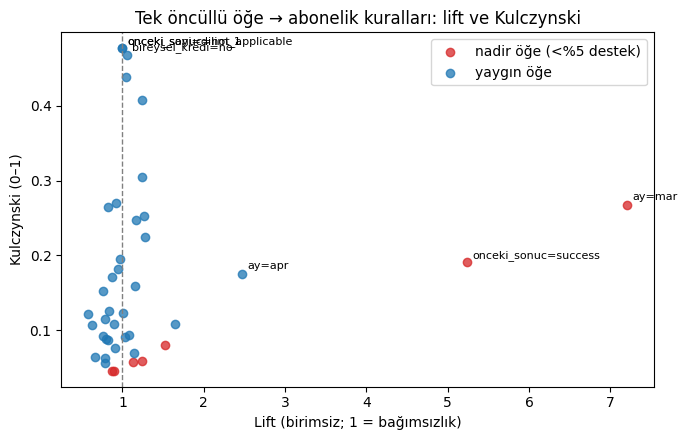

In [17]:
taban_oran=sonuc.mean(); kayit_sayisi=len(islem); evet=islem.hedef.eq("yes").to_numpy(); min_ortak=int(np.ceil(.002*kayit_sayisi))
tek_satirlar=[]
for sutun in islem.columns.drop("hedef"):
    for deger in sorted(islem[sutun].astype(str).unique()):
        maske=islem[sutun].astype(str).eq(deger).to_numpy(); a=int(maske.sum()); ab=int((maske&evet).sum())
        if ab<min_ortak: continue
        guven=ab/a; kapsama=ab/evet.sum()
        tek_satirlar.append({"oncul":f"{sutun}={deger}","oncul_destegi":a/kayit_sayisi,"guven_P(evet|A)":guven,"kapsama_P(A|evet)":kapsama,
            "lift":guven/taban_oran,"kulczynski":.5*(guven+kapsama),"IR":abs(a/kayit_sayisi-taban_oran)/(a/kayit_sayisi+taban_oran-ab/kayit_sayisi),"nadir_oge(<%5)":a/kayit_sayisi<.05})
tek_oncul=pd.DataFrame(tek_satirlar)
tek_oncul["lift_sirasi"]=tek_oncul.lift.rank(ascending=False,method="min").astype(int)
tek_oncul["kulczynski_sirasi"]=tek_oncul.kulczynski.rank(ascending=False,method="min").astype(int)
print("Lift'e göre ilk 8"); display(tek_oncul.sort_values("lift",ascending=False).head(8).round(4))
print("Kulczynski'ye göre ilk 8"); display(tek_oncul.sort_values("kulczynski",ascending=False).head(8).round(4))
spearman_lk=tek_oncul[["lift","kulczynski"]].corr(method="spearman").iloc[0,1]
nadir_ust=tek_oncul.sort_values("lift",ascending=False).iloc[0]; kulc_ust=tek_oncul.sort_values("kulczynski",ascending=False).iloc[0]
display(Markdown(f"**Hesaplanan karşılaştırma:** {len(tek_oncul)} tek öncüllü kuralda lift ile Kulczynski sıralamalarının Spearman korelasyonu **{spearman_lk:.2f}**. "
    f"Lift'te birinci `{nadir_ust.oncul}` (destek %{100*nadir_ust.oncul_destegi:.2f}, lift {nadir_ust.lift:.2f}) Kulczynski'de **{int(nadir_ust.kulczynski_sirasi)}.** sıradadır, çünkü aboneliklerin yalnız %{100*nadir_ust['kapsama_P(A|evet)']:.1f}'ini kapsar. "
    f"Kulczynski'de birinci `{kulc_ust.oncul}` (destek %{100*kulc_ust.oncul_destegi:.1f}) ise lift {kulc_ust.lift:.2f} ile lift'te **{int(kulc_ust.lift_sirasi)}.** sıradadır; IR={kulc_ust.IR:.2f}."))
tek_oncul.to_csv(cikti/"lift_kulczynski_karsilastirma.csv",index=False)
fig,eksen=plt.subplots(figsize=(7,4.5))
for nadir_mi,renk,etiket in [(True,"tab:red","nadir öğe (<%5 destek)"),(False,"tab:blue","yaygın öğe")]:
    alt=tek_oncul[tek_oncul["nadir_oge(<%5)"]==nadir_mi]; eksen.scatter(alt.lift,alt.kulczynski,c=renk,label=etiket,alpha=.75)
for _,r in pd.concat([tek_oncul.nlargest(3,"lift"),tek_oncul.nlargest(3,"kulczynski")]).drop_duplicates("oncul").iterrows():
    eksen.annotate(r.oncul,(r.lift,r.kulczynski),fontsize=8,xytext=(4,3),textcoords="offset points")
eksen.axvline(1,color="gray",ls="--",lw=1); eksen.set_xlabel("Lift (birimsiz; 1 = bağımsızlık)"); eksen.set_ylabel("Kulczynski (0–1)")
eksen.set_title("Tek öncüllü öğe → abonelik kuralları: lift ve Kulczynski"); eksen.legend(); plt.tight_layout(); plt.show()


**Grafik ve sonuçların yorumu:** Her nokta bir tek öncüllü kuralı gösterir. Yatay eksen lift, dikey eksen Kulczynski değeridir; kesikli lift=1 çizgisi bağımsızlık referansıdır. Kırmızı noktalar öncül desteği %5'in altında, mavi noktalar ise diğer kurallardır. 41 kural için Spearman korelasyonu 0,35'tir; ölçütlerin sıralamaları sınırlı ölçüde aynı yönde değişmektedir. Burada korelasyonun anlamlılığına ilişkin ayrı bir test yapılmamıştır.

| Öncül | Öncül desteği | Güven | Aboneleri kapsama | Lift | Kulczynski | IR |
|---|---:|---:|---:|---:|---:|---:|
| Mart | %0,71 | %48,45 | %5,14 | 7,20 | 0,2679 | 0,8476 |
| Önceki başarı | %0,58 | %35,24 | %3,04 | 5,24 | 0,1914 | 0,8653 |
| Önceki sonuç uygulanamaz | %89,44 | %6,66 | %88,61 | 0,99 | 0,4764 | 0,9169 |
| Konut kredisi yok | %42,33 | %8,36 | %52,61 | 1,24 | 0,3048 | 0,7822 |

Mart kuralı lift'te birinci, Kulczynski'de sekizincidir. %48,45 güven, %6,73 taban oranın çok üzerindedir; ancak Mart, tüm aboneliklerin yalnız %5,14'ünü içerir. Önceki başarı da lift'te ikinci iken Kulczynski'de 14. sıradadır. Ters örnek olan `onceki_sonuc=not_applicable`, Kulczynski'de eşit birinciliğe ve lift'te 20. sıraya sahiptir; kapsaması çok yüksek olsa da güveni taban oranın biraz altında, lift'i yaklaşık 0,99'dur. Bu durum güçlü pozitif zenginleşme kanıtı değildir. IR≈0,92, marjinal yaygınlıkların belirgin biçimde dengesiz olduğunu görünür kılar. Konut kredisi yok kuralı daha ılımlı lift ile daha geniş abone kapsamasını birleştirir.

Bu sonuçlar Wu, Chen ve Han (2010) çerçevesinin bu veri üzerindeki somut karşılığıdır: iki yönlü ölçüt ve dengesizlik birlikte okunduğunda nadir ancak seçici profiller ile yaygın fakat az seçici profiller ayırt edilir. Null-invariance, lift'in yararsızlığı veya Kulczynski'nin her durumda üstünlüğü anlamına gelmez; iki ölçüt farklı bilgi taşır.

**Karar:** Banka için keşifsel hedefleme adayları seçerken güven ve lift ile seçicilik, destek ve kapsama ile erişim, Kulczynski ve IR ile iki yönlü ilişki birlikte değerlendirilir. Nadir profilleri yalnızca lift'e göre önceliklendirmek az müşteriye ulaşabilir; yaygın profilleri yalnızca Kulczynski'ye göre seçmek ise taban orana göre gerçek zenginleşmeyi gözden kaçırabilir. Bu ölçütler kampanya maliyetini, müdahalenin nedensel etkisini veya gelecek dönem performansını doğrudan ölçmez.

### Ek analiz · Birliktelik kurallarının güven değerine %95 aralık

Kural güveni P(abonelik=yes | öncül), öncülü sağlayan kayıtlar içindeki abonelik oranıdır. Her mevcut kural için öncül ve ortak sayıları yeniden sayılır, eski destek/güven ile eşitliği denetlenir ve güven için **Wilson %95 aralığı** hesaplanır. Payda tüm veri değil, öncülü sağlayan kayıtların sayısıdır. Önceki destek/güven/lift/Kulczynski değerleri ve kural seçimi korunur; aralık eklemek yeni kurallar keşfetmez ve mevcut sıralamayı yeniden optimize etmez.


In [18]:
# EK ANALIZ: Her mevcut kuralin guveni icin Wilson araligi.
# Hicbir destek, guven esigi, kural sirasi veya eski sonuc degistirilmez.
kural_ga_satirlari=[]
for _,satir in kurallar.iterrows():
    maske=np.ones(len(islem),dtype=bool)
    for oge in satir.antecedents:
        sutun,deger=oge.split("=",1)
        maske &= islem[sutun].astype(str).eq(deger).to_numpy()
    oncul_sayisi=int(maske.sum())
    ortak_sayisi=int((maske & islem.hedef.eq("yes").to_numpy()).sum())
    guven=ortak_sayisi/oncul_sayisi
    assert np.isclose(guven,satir["confidence"])
    assert np.isclose(ortak_sayisi/len(islem),satir["support"])
    alt,ust=wilson_araligi(ortak_sayisi,oncul_sayisi)
    kural_ga_satirlari.append({"kural":" & ".join(sorted(satir.antecedents))+" -> hedef=yes", "oncul_sayisi":oncul_sayisi,"ortak_sayisi":ortak_sayisi,"destek":satir["support"],"guven":guven,"guven_alt_95":float(alt),"guven_ust_95":float(ust),"lift":satir["lift"],"kulczynski":satir["kulczynski"]})
kural_guven_ga=pd.DataFrame(kural_ga_satirlari).sort_values("kulczynski",ascending=False)
print("Mevcut pozitif kurallarin tamami; guven ve araliklar 0-1 olceginde")
display(kural_guven_ga.reset_index(drop=True))
for _,satir in kural_guven_ga.head(3).iterrows():
    display(Markdown(f"**Hesaplanan yorum — {satir.kural}:** {satir.ortak_sayisi}/{satir.oncul_sayisi} kayıtta abonelik; güven **%{100*satir.guven:.2f}**, noktasal %95 Wilson aralığı **[%{100*satir.guven_alt_95:.2f}; %{100*satir.guven_ust_95:.2f}]**. Bu aralık, sabit bir profil ve bağımsız kayıtlar varsayımına dayanır; çok sayıda adaydan kural seçmenin iyimserliğini veya gelecek dönemdeki değişimi kapsamaz."))
kural_guven_ga.to_csv(cikti/"kural_guven_araliklari.csv",index=False)


Mevcut pozitif kurallarin tamami; guven ve araliklar 0-1 olceginde


,kural,oncul_sayisi,ortak_sayisi,destek,guven,guven_alt_95,guven_ust_95,lift,kulczynski
0,ay=mar & kampanya=dilim_1 -> hedef=yes,210,107,0.002958,0.509524,0.442350,0.576356,7.574376,0.276751
1,ay=mar & iletisim=cellular -> hedef=yes,238,118,0.003263,0.495798,0.432851,0.558879,7.370339,0.272149
2,ay=mar & bireysel_kredi=no -> hedef=yes,241,119,0.003290,0.493776,0.431249,0.556498,7.340275,0.271343
3,ay=mar -> hedef=yes,258,125,0.003456,0.484496,0.424190,0.545257,7.202325,0.267937
4,ay=mar & onceki_sayi=dilim_1 -> hedef=yes,234,113,0.003124,0.482906,0.419675,0.546689,7.178686,0.264675
5,ay=mar & onceki_sonuc=not_applicable -> hedef=yes,234,113,0.003124,0.482906,0.419675,0.546689,7.178686,0.264675
6,ay=mar & konut_kredisi=no -> hedef=yes,190,92,0.002544,0.484211,0.414170,0.554876,7.198079,0.261012
7,ay=apr & konut_kredisi=no -> hedef=yes,701,274,0.007576,0.390870,0.355438,0.427492,5.810519,0.251744
8,onceki_sonuc=success -> hedef=yes,210,74,0.002046,0.352381,0.290950,0.419115,5.238354,0.191398
9,onceki_sayi=dilim_2 & onceki_sonuc=success -> ...,210,74,0.002046,0.352381,0.290950,0.419115,5.238354,0.191398


**Hesaplanan yorum — ay=mar & kampanya=dilim_1 -> hedef=yes:** 107/210 kayıtta abonelik; güven **%50.95**, noktasal %95 Wilson aralığı **[%44.23; %57.64]**. Bu aralık, sabit bir profil ve bağımsız kayıtlar varsayımına dayanır; çok sayıda adaydan kural seçmenin iyimserliğini veya gelecek dönemdeki değişimi kapsamaz.

**Hesaplanan yorum — ay=mar & iletisim=cellular -> hedef=yes:** 118/238 kayıtta abonelik; güven **%49.58**, noktasal %95 Wilson aralığı **[%43.29; %55.89]**. Bu aralık, sabit bir profil ve bağımsız kayıtlar varsayımına dayanır; çok sayıda adaydan kural seçmenin iyimserliğini veya gelecek dönemdeki değişimi kapsamaz.

**Hesaplanan yorum — ay=mar & bireysel_kredi=no -> hedef=yes:** 119/241 kayıtta abonelik; güven **%49.38**, noktasal %95 Wilson aralığı **[%43.12; %55.65]**. Bu aralık, sabit bir profil ve bağımsız kayıtlar varsayımına dayanır; çok sayıda adaydan kural seçmenin iyimserliğini veya gelecek dönemdeki değişimi kapsamaz.

**Yorum ve karar:** Yaklaşık %51 güvene sahip bir profilin aralığı, o oranın nokta tahmininden daha belirsiz olduğunu görünür kılar. Bu, “aynı profile arama yapınca kesin %51 başarı elde edilir” yorumunu desteklemez. İlk üç kural aynı Mart kayıtlarını paylaşabileceğinden aralıklar da bağımsız üç kanıt değildir. Ayrı aralıkların örtüşmesi kuralların eşitliğini veya farklılığını sınayan bir test sayılmaz.

Buradaki Wilson aralıkları **öncül sabit kabul edilerek hesaplanan keşifsel, noktasal aralıklardır**. Kurallar çok sayıda adaydan seçilmiş, destek eşiği de keşif sırasında değiştirilmiştir; nominal %95 kapsama seçilmiş kurallar için garanti edilmez. Genel taban oranıyla iç içe kayıtlar kullanıldığı için kural aralığını genel oranın aralığıyla karşılaştırıp bağımsız iki grup testi yapılmaz. Lift ve Kulczynski için bu hücrede güven aralığı hesaplanmamıştır; güven sınırını taban oranına bölmek lift'in bütün belirsizliğini kapsamaz.

**Bu çalışmanın kararı:** Bu profiller yeni veriyle doğrulanacak aday ilişkilerdir. Güven aralığı eklemek örneklem büyüklüğünü görünür kılar; geleceğe genellemeyi doğrulamaz. Doğrulama için öncüller ve eşikler sabitlenerek yeni, henüz incelenmemiş dönemde destek/güven tekrar ölçülmelidir. Mevcut ileri dönem daha önce incelendiği için burada yeni dokunulmamış doğrulama diye kullanılmamıştır.

Somut karşılaştırmada Mart + kampanya dilim 1 kuralı 107/210 olumlu kayıtla %50,95 güvene ve [%44,23; %57,64] aralığına sahiptir. Nisan + konut kredisi yok kuralı ise 274/701 ile %39,09 güven ve [%35,54; %42,75] aralığı verir. İkinci profilin güveni daha düşük, gözlenen olumlu sayısı ve ortak desteği daha yüksektir; daha dar aralık daha büyük öncül örneklemiyle uyumludur. Bu iki aday farklı erişim/seçicilik dengeleri sunar. En düşük güvenli Nisan + yönetim mesleği kuralının aralığı [%19,38; %26,73] olup keşif aşamasında kullanılan %20 eşiğinin altına da uzanır. Dolayısıyla eşik üstünde seçilmiş nokta tahminleri kesin bir genelleme olarak okunmamalıdır.

In [19]:
from sklearn.inspection import permutation_importance
onem=permutation_importance(en_iyi,gelecek,gelecek_sonuc,scoring="average_precision",n_repeats=5,random_state=TOHUM,n_jobs=1)
onemler=pd.Series(onem.importances_mean,index=egitim.columns).sort_values(ascending=False)
onem_tablosu=pd.DataFrame({"AP_azalmasi_ortalama":onem.importances_mean,"AP_azalmasi_std":onem.importances_std},index=gelecek.columns).sort_values("AP_azalmasi_ortalama",ascending=False)
display(onem_tablosu.head(10))
onem_tablosu.to_csv(cikti/"ileri_donem_permutasyon_onemi.csv")
for _,satir in kurallar.sort_values("kulczynski",ascending=False).head(3).iterrows():
    ogeler=sorted(satir.antecedents)
    display(Markdown(f"**Yorum:** {ogeler} koşullarında abonelik oranı %{100*satir['confidence']:.1f}; taban oranına göre lift {satir['lift']:.2f}, Kulczynski {satir['kulczynski']:.3f}. Bu profil, gözlenen kampanyadaki ilişkiyi gösterir; bu gruba arama yapmanın ek etkisini ölçmez. Öncül sütunlarının modelin ilk beş önemiyle kesişimi: {set(o.split('=')[0] for o in ogeler)&set(onemler.head(5).index)}."))

print("Alan yorumu: Mart/Nisan kurallari mevsim, kampanya politikasi ve musteri bilesimini birlikte yansitabilir; takvim nedensel etki degildir.")
print("Alan yorumu: onceki_sonuc=success daha onceki olumlu temas gecmisini gosterir; yeni musteriye ayni duzeyde genellenemez.")
print("Alan yorumu: konut kredisi/meslek/egitim profilleri gozlemseldir; kredi veya egitim durumunu degistirmenin aboneligi degistirecegi sonucu cikarilamaz.")


,AP_azalmasi_ortalama,AP_azalmasi_std
onceki_sonuc,0.077044,0.001332
ay,0.059387,0.005737
yas,0.022082,0.002774
bakiye,0.007893,0.000668
gun,0.006792,0.000980
medeni_durum,0.004461,0.001612
konut_kredisi,0.003075,0.000522
iletisim,0.002504,0.000748
onceki_gun,0.002155,0.000886
egitim,0.001410,0.000548


**Yorum:** ['ay=mar', 'kampanya=dilim_1'] koşullarında abonelik oranı %51.0; taban oranına göre lift 7.57, Kulczynski 0.277. Bu profil, gözlenen kampanyadaki ilişkiyi gösterir; bu gruba arama yapmanın ek etkisini ölçmez. Öncül sütunlarının modelin ilk beş önemiyle kesişimi: {'ay'}.

**Yorum:** ['ay=mar', 'iletisim=cellular'] koşullarında abonelik oranı %49.6; taban oranına göre lift 7.37, Kulczynski 0.272. Bu profil, gözlenen kampanyadaki ilişkiyi gösterir; bu gruba arama yapmanın ek etkisini ölçmez. Öncül sütunlarının modelin ilk beş önemiyle kesişimi: {'ay'}.

**Yorum:** ['ay=mar', 'bireysel_kredi=no'] koşullarında abonelik oranı %49.4; taban oranına göre lift 7.34, Kulczynski 0.271. Bu profil, gözlenen kampanyadaki ilişkiyi gösterir; bu gruba arama yapmanın ek etkisini ölçmez. Öncül sütunlarının modelin ilk beş önemiyle kesişimi: {'ay'}.

Alan yorumu: Mart/Nisan kurallari mevsim, kampanya politikasi ve musteri bilesimini birlikte yansitabilir; takvim nedensel etki degildir.
Alan yorumu: onceki_sonuc=success daha onceki olumlu temas gecmisini gosterir; yeni musteriye ayni duzeyde genellenemez.
Alan yorumu: konut kredisi/meslek/egitim profilleri gozlemseldir; kredi veya egitim durumunu degistirmenin aboneligi degistirecegi sonucu cikarilamaz.


**Yorum – birliktelik kuralları ve model öznitelik önemi**

Permütasyon önemi, eğitilmiş modelin ileri dönem verisinde bir özniteliğin değerleri karıştırıldığında ortalama AP kaybını ölçer. İlk beş öznitelik önceki sonuç (0,0770), ay (0,0594), yaş (0,0221), bakiye (0,0079) ve gündür (0,0068). Büyük bir düşüş, bu modelin o değerlendirme kümesindeki sıralamasının ilgili değişkene dayandığını düşündürür; nedensel etki ya da tek başına tahmin gücü değildir.

Yönerge 4.3'te istenen örtüşme karşılaştırmasında 12 kuraldan 10'unun ay, ikisinin önceki sonuç öğesini içerdiği görülür. Kulczynski sıralamasındaki ilk üç kuralın hepsi Mart koşulunu taşır; bu nedenle ilk beş model önemindeki değişkenlerle doğrudan ortak sütun ay'dır. Önceki başarıyı içeren iki kural aynı kayıt kümesini kapsadığı halde, modelde önceki sonuç en büyük ortalama AP düşüşünü vermiştir. Böylece iki yaklaşım kampanya zamanlaması ve geçmiş başarı sinyallerinde örtüşmektedir.

Yaş, bakiye ve gün değişkenleri ilk beş model önemindedir, ancak kısa pozitif kural listesinde bulunmaz. Bunun olası nedenleri üçte birlik kantillerin yaşın iki uç grubunu ayrı ayrı yakalayamaması, güven/destek filtresi, bazı değişkenlerin işlem tablosuna alınmaması (ör. gün) ve değişkenlerin diğerleriyle birlikte tahmine katkıda bulunabilmesidir. Kuralda bulunmaması değersiz olduğu anlamına gelmez. Konut kredisi modelde yedinci sıradadır (ortalama AP kaybı 0,0031), buna rağmen Nisan + konut kredisi yok kuralında görülür; bu, belirli alt gruptaki bir ilişkinin bütün modeldeki önemle aynı olmayabileceğini gösterir.

**Karar:** Örtüşen ay ve önceki sonuç sinyalleri Proje 2 için incelenmeye değer adaylardır. Geliştirme kayıtlarındaki kurallar ile prevalansı farklı ileri dönemde hesaplanan öznitelik önemi birbirini tamamlar, ancak bağımsız tekrarlama veya etkileşim testi değildir. Beş permütasyondan elde edilen standart sapmalar yeni bir örneklemin veya yeniden eğitilmiş modelin belirsizliğini kapsamaz. İlişkili değişkenler önem değerlerini paylaşabilir ya da maskeleyebilir.

## WEKA · ortak veriyle bağımsız kontrol
Bölüm 1’deki ZeroR ve J48 (C=0,25, M=2) kontrolü korunur. Bu bölüm aynı hazırlanmış verinin Türkçe sütun adlarıyla ZeroR ve J48 (M=2) çalıştırmasını yapar; sonuçları güncel loglardan okuyun. C4.5/CART ve Python/WEKA katları eşdeğer değildir.

Birliktelikte aynı ayrıklaştırılmış tablo, güven 0,20 ve en az ceil(0,002×N) ortak kayıt kullanılır. WEKA CAR kurallarından hedef=yes ve en çok iki öncül filtrelenerek Python ile tüm öncül kümeleri ve sayımlar karşılaştırılır.

**Doğrulama yaklaşımı:** WEKA kontrolü, aynı hazırlanmış geliştirme verisi üzerinde iki farklı yazılım uygulamasının davranışını karşılaştırır. Sınıflandırmada çoğunluk tahmini ve ağaç davranışı referans alınırken birliktelikte birebir sayımlara odaklanılır. Yönerge 4.3'ün asıl bağımsız uygulama kontrolü Apriori'ye ilişkindir; bu nedenle J48 karşılaştırması tamamlayıcıdır, Apriori doğrulamasının yerine geçmez.

In [20]:
def arff_yaz(tablo,yol):
    import csv
    def tirnak(deger):
        return "'"+str(deger).replace("\\","\\\\").replace("'","\\'")+"'"
    satirlar=["@relation banka"]
    for sutun in tablo:
        if pd.api.types.is_numeric_dtype(tablo[sutun]): tur="numeric"
        else: tur="{"+",".join(tirnak(deger) for deger in sorted(tablo[sutun].dropna().unique()))+"}"
        satirlar.append("@attribute "+tirnak(sutun)+" "+tur)
    satirlar.append("@data")
    for satir in tablo.itertuples(index=False,name=None):
        satirlar.append(",".join("?" if pd.isna(deger) else str(deger) if isinstance(deger,(int,float,np.number)) else tirnak(deger) for deger in satir))
    Path(yol).write_text("\n".join(satirlar),encoding="utf-8")
weka_veri=egitim.copy(); weka_veri["hedef"]=sonuc.map({0:"no",1:"yes"})
arff_yaz(weka_veri,cikti/"weka_siniflandirma.arff")
arff_yaz(islem,cikti/"weka_birliktelik.arff")
java_yolu=JAVA
weka_sinif_yolu=weka_classpath
for ad,secenek in [("ZeroR",["weka.classifiers.rules.ZeroR"]),("J48",["weka.classifiers.trees.J48","-C","0.25","-M","2"])]:
    komut=[java_yolu,"--add-opens","java.base/java.lang=ALL-UNNAMED","-cp",weka_sinif_yolu]+secenek+["-t",str(cikti/"weka_siniflandirma.arff"),"-x","10","-s","42"]
    islem_sonucu=subprocess.run(komut,capture_output=True,text=True)
    if islem_sonucu.returncode or "Exception" in islem_sonucu.stderr or "exception:" in islem_sonucu.stderr: raise RuntimeError(islem_sonucu.stderr)
    (cikti/("weka_"+ad+".txt")).write_text(islem_sonucu.stdout)
    print(ad,islem_sonucu.stdout[-4500:])
komut=[java_yolu,"--add-opens","java.base/java.lang=ALL-UNNAMED","-Xmx2g","-cp",weka_sinif_yolu,"weka.associations.Apriori","-t",str(cikti/"weka_birliktelik.arff"),"-A","-c","last","-T","0","-C","0.2","-M",str(np.ceil(.002*len(islem))/len(islem)),"-U","1","-N","2147483647"]
islem_sonucu=subprocess.run(komut,capture_output=True,text=True)
if islem_sonucu.returncode or "Exception" in islem_sonucu.stderr or "exception:" in islem_sonucu.stderr: raise RuntimeError(islem_sonucu.stderr)
(cikti/"weka_Apriori.txt").write_text(islem_sonucu.stdout)
print(islem_sonucu.stdout[:1500])


ZeroR [0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

=== Classifier model (full training set) ===

ZeroR predicts class value: no

Time taken to build model: 0.08 seconds

Time taken to test model on training data: 0.34 seconds

=== Error on training data ===

Correctly Classified Instances       33735               93.2731 %
Incorrectly Classified Instances      2433                6.7269 %
Kappa statistic                          0     
Mean absolute error                      0.1255
Root mean squared error                  0.2505
Relative absolute error                100      %
Root relative squared error            100      %
Total Number of Instances            36168     


=== Detailed Accuracy By Cla

**Yorum – WEKA sınıflandırma kontrolü (10 kat, yalnız geliştirme verisi):**
- **ZeroR** her kayda "hayır" der. Doğruluğu %93,27'dir; bu, 1 − 0,0673 eder ve Python'daki DummyClassifier ile aynıdır. "Evet" sınıfının PRC Area değeri 0,067, Python baseline AP'sine (0,067) yuvarlatılmış değer düzeyinde yakındır. Bu, iki ortamın aynı veriyi ve aynı hedef dağılımını gördüğünü doğrular.
- **J48** (C4.5, C=0,25, M=2): Doğruluk %93,25'tir, yani ZeroR'dan bile düşüktür (2.440 hata ve 2.433 hata). Buna rağmen J48 abonelerin %11,3'ünü yakalar (275/2.433), kesinliği %49,4, "evet" PRC Area değeri 0,188, ROC 0,623, kappa 0,163'tür. Doğruluk, işe yarayan bir modeli işe yaramayandan kötü gösterir. Bu da doğruluğun ölçüt olarak kullanılmamasının somut gerekçesidir.
- **Python ağaçlarıyla tutarlılık:** Python tarafında ortak 10 kat üzerinde ağırlıksız CART'ın AP'si 0,188 (derinlik 6) ile 0,215 (sınırsız) arasındadır. Duyarlılık %6,6–9,2, kesinlik %47–52'dir. J48 aynı büyüklük aralığındadır. Kalan farklar beklenen nedenlerden gelir: bilgi kazancı oranı ile Gini farkı, budama, kategorilerin bire-bir kodlanmadan doğrudan bölünmesi ve farklı kat atamaları.

**Söyleyemeyeceğimiz:** PRC Area ile sklearn AP birebir aynı hesap değildir; küçük farklar tanım farkı olabilir.

Sonuçların pratik yorumu, pozitif hedefin az görülmesi nedeniyle doğruluk yerine sınıf bazlı duyarlılık, kesinlik ve sıralama başarısının birlikte ele alınmasıdır. ZeroR'un hiç pozitif tahmin etmemesi, yüksek doğruluğun tek başına pazarlama hedefini karşılamadığını gösterir. J48 ise pozitiflerin bir bölümünü belirleyebilir fakat çok sayıda aboneyi kaçırır. Aynı dağılımı kullanan iki taban modelinin uyumu veri hazırlama kontrolü olarak değerlidir; J48 ile CART'ın birebir tahmin ve ölçüt eşitliği beklentisi yoktur.

WEKA Apriori çıktısının tamamı okunur. Kontrol yalnız hedef=yes, bir–iki öncül ve belirtilen destek/güven eşikleri için tamlık iddiası taşır; diğer uzunluklar ve negatif hedef kuralları kapsam dışıdır.

Öncülün kapsadığı ve öncül ile hedefin birlikte gerçekleştiği kayıt sayıları ayrı ayrı doğrulanır. Ortak sayım desteğin payını, öncül sayımı güvenin paydasını oluşturur. Sayımlar ve toplam N aynı olduğunda bu iki ölçüt ve aynı pozitif hedef için lift de aynı temele dayanır. Kural kümelerinin eşitliği ayrıca denetlendiğinden yalnız seçilmiş birkaç örneğin tutmasıyla yetinilmez.

In [21]:
import re
metin=(cikti/"weka_Apriori.txt").read_text()
kontrol=[]
weka_kume=set()
for satir in metin.splitlines():
    if "==>" not in satir or "hedef=yes" not in satir: continue
    sol,sag=satir.split("==>",1)
    eslesmeler=re.findall(r"([a-z_]+)=([^ ]+)",sol)
    if not 1<=len(eslesmeler)<=2: continue
    maske=np.ones(len(islem),dtype=bool)
    for sutun,deger in eslesmeler:
        maske &= islem[sutun].astype(str).eq(deger).to_numpy()
    ortak_weka=re.search(r"hedef=yes\s+(\d+)",sag)
    oncul_weka=re.search(r"\s(\d+)\s*$",sol)
    assert ortak_weka and oncul_weka, "WEKA sayim bicimi degisti"
    anahtar=frozenset(sutun+"="+deger for sutun,deger in eslesmeler)
    weka_kume.add(anahtar)
    ortak=int((maske & islem.hedef.eq("yes").to_numpy()).sum())
    kontrol.append({"kural":" & ".join(sorted(anahtar)),"python_oncul":int(maske.sum()),
        "weka_oncul":int(oncul_weka.group(1)),"python_ortak":ortak,"weka_ortak":int(ortak_weka.group(1))})
kontrol=pd.DataFrame(kontrol)
python_kume=set(kurallar.antecedents)
assert len(kontrol)>0, "WEKA pozitif kural cikarmadi"
assert (kontrol.python_ortak==kontrol.weka_ortak).all()
assert (kontrol.python_oncul==kontrol.weka_oncul).all()
assert weka_kume==python_kume, {"yalniz_weka":weka_kume-python_kume,"yalniz_python":python_kume-weka_kume}
print("Tum oncul kumeleri ve oncul/ortak sayimlari eslesti:",len(weka_kume))
display(kontrol); kontrol.to_csv(cikti/"weka_kural_kontrol.csv",index=False)
# Derinlik ve agirlik ayri faktorler; tum modeller ayni 10 katta.
weka_katlar=list(StratifiedKFold(10,shuffle=True,random_state=TOHUM).split(egitim,sonuc))
kiyas_modelleri={"Baseline":modeller["Baseline"]}
for derinlik in [6,None]:
    for agirlik in [None,"balanced"]:
        kiyas_modelleri[f"CART derinlik={derinlik}, agirlik={agirlik}"]=hat(DecisionTreeClassifier(
            max_depth=derinlik,min_samples_leaf=30,class_weight=agirlik,random_state=TOHUM))
kiyas_satirlari=[]
for ad,kiyas_modeli in kiyas_modelleri.items():
    kontrol_skor=cross_validate(kiyas_modeli,egitim,sonuc,cv=weka_katlar,
        scoring={**olcutler,"Dogruluk":"accuracy"},n_jobs=1,error_score="raise")
    for anahtar,deger in kontrol_skor.items():
        if anahtar.startswith("test_"):
            kiyas_satirlari.append({"model":ad,"olcut":anahtar[5:],"ortalama":deger.mean(),"std":deger.std(ddof=1)})
cart_kiyas=pd.DataFrame(kiyas_satirlari)
display(cart_kiyas.pivot(index="model",columns="olcut",values=["ortalama","std"]))
cart_kiyas.to_csv(cikti/"kontrollu_cart.csv",index=False)
puanlar.to_csv(cikti/"tum_cv_skorlari.csv",index=False)
# Protokol tek seferde yazılır; JSON sonsuz sayı içermediği için aralık uçları metinle saklanır.
protokol={"tohum":TOHUM,"gelistirme_sinir":int(sinir),"cv":"5 kat x 2 tekrar; katmanli","olcut":"average_precision","secilen":en_iyi_ad,
    "veri_sha256":hashlib.sha256(veri_yolu.read_bytes()).hexdigest(),"temel_commit":"b4c394ad17ed5d2724b661952d75027a732eac36",
    "mcnemar":{"modeller":ilk_iki,"b":int(b),"c":int(c),"p":float(p_degeri),"esik":0.5},
    "dietterich_5x2cv":{olcut:{k:float(v) for k,v in satir.items()} for olcut,satir in bes_iki_tablo.to_dict(orient="index").items()},
    "optimist_yanlilik":{"best_score_3kat":float(ic_iyi),"best_score_ayni_katlar":float(ic_iyi_ayni),"ic_ice_dis_ortalama":float(dis_skor.mean()),"ic_ice_dis_std":float(dis_skor.std(ddof=1))},
    "on_isleme":{"pdays":"-1 korunur","poutcome":"not_applicable","kategorik_doldurma":"most_frequent","lojistik_agirlik":None,"j48_min_yaprak":2},
    "sinirlar":{k:[("-inf" if x<0 else "inf") if not np.isfinite(x) else float(x) for x in v] for k,v in sinirlar.items()},
    "surumler":{"python":sys.version,"sklearn":sklearn.__version__,"pandas":pd.__version__,"numpy":np.__version__,"scipy":scipy.__version__}}
(cikti/"protokol.json").write_text(json.dumps(protokol,ensure_ascii=False,indent=2,allow_nan=False))
print("protokol.json yazıldı.")


Tum oncul kumeleri ve oncul/ortak sayimlari eslesti: 12


,kural,python_oncul,weka_oncul,python_ortak,weka_ortak
0,ay=mar & kampanya=dilim_1,210,210,107,107
1,ay=mar & iletisim=cellular,238,238,118,118
2,ay=mar & bireysel_kredi=no,241,241,119,119
3,ay=mar,258,258,125,125
4,ay=mar & konut_kredisi=no,190,190,92,92
5,ay=mar & onceki_sonuc=not_applicable,234,234,113,113
6,ay=mar & onceki_sayi=dilim_1,234,234,113,113
7,ay=apr & konut_kredisi=no,701,701,274,274
8,onceki_sonuc=success,210,210,74,74
9,onceki_sayi=dilim_2 & onceki_sonuc=success,210,210,74,74


ortalama                             \
olcut                                       AP Dengeli_dogruluk  Dogruluk   
model                                                                       
Baseline                              0.067269         0.500000  0.932731   
CART derinlik=6, agirlik=None         0.188249         0.530840  0.932979   
CART derinlik=6, agirlik=balanced     0.194691         0.618527  0.726225   
CART derinlik=None, agirlik=None      0.215054         0.542335  0.932012   
CART derinlik=None, agirlik=balanced  0.203925         0.611594  0.683477   

                                                                               \
olcut                                Duyarlilik        F1  Kesinlik   ROC_AUC   
model                                                                           
Baseline                               0.000000  0.000000  0.000000  0.500000   
CART derinlik=6, agirlik=None          0.066186  0.116397  0.515999  0.649421   
CART derinlik=6, agirlik=balanced      0.494078  0.200055  0.129310  0.672622   
CART derinlik=None, agirlik=None       0.092080  0.153497  0.470359  0.656781   
CART derinlik=None, agirlik=balanced   0.528538  0.183507  0.111057  0.654504   

                                           std                             \
olcut                                       AP Dengeli_dogruluk  Dogruluk   
model                                                                       
Baseline                              0.000131         0.000000  0.000131   
CART derinlik=6, agirlik=None         0.015713         0.009158  0.000910   
CART derinlik=6, agirlik=balanced     0.016168         0.014083  0.071171   
CART derinlik=None, agirlik=None      0.020056         0.011454  0.002009   
CART derinlik=None, agirlik=balanced  0.017657         0.016094  0.012133   

                                                                               
olcut                                Duyarlilik        F1  Kesinlik   ROC_AUC  
model                                                                          
Baseline                               0.000000  0.000000  0.000000  0.000000  
CART derinlik=6, agirlik=None          0.019463  0.031534  0.045412  0.016396  
CART derinlik=6, agirlik=balanced      0.081658  0.022931  0.028375  0.017640  
CART derinlik=None, agirlik=None       0.023010  0.035451  0.074596  0.014605  
CART derinlik=None, agirlik=balanced   0.032510  0.010690  0.006664  0.018787

protokol.json yazıldı.


**Yorum – WEKA Apriori ve kontrollü CART**

**Birliktelik doğrulaması:** WEKA ve Python arasında hedef=yes, 1–2 öncül, destek ≥0,002 ve güven ≥0,20 kapsamındaki 12 kuralın tüm öncül kümeleri eşleşmiştir. Tabloda öncül ve ortak sayımlar ayrı ayrı eşittir. Örneğin Mart kuralı 258 öncül ve 125 ortak kayıt, Nisan + konut kredisi yok 701 öncül ve 274 ortak kayıt verir. İki uygulamada da aynı kayıt temsili kullanıldığından bu bulgu hesaplamanın ve kural çıkarma işleminin uygulamalar arası tutarlılığını destekler; yeni veriyle istatistiksel doğrulama değildir. Yönerge 4.3'ün WEKA Apriori karşılaştırması bu kapsamda karşılanmıştır.

**Kontrollü ağaç kıyası:** Python'da aynı 10 kat üzerinde ağırlık ve derinlik ayrı faktörler olarak değiştirilmiştir. Derinlik 6'da dengeli ağırlık kullanılması duyarlılığı %6,62'den %49,41'e yükseltmiş, kesinliği %51,60'tan %12,93'e, doğruluğu %93,30'dan %72,62'ye düşürmüştür. F1 0,116'dan 0,200'e, AP ise 0,188'den 0,195'e çıkmıştır. Ağırlıklar ağacın eğitimini de değiştirir; sonuç yalnızca karar eşiği değişimine indirgenemez. Ağırlıksız durumda derinlik sınırının kaldırılması AP'yi 0,188'den 0,215'e çıkarmış, duyarlılığı %6,62'den %9,21'e yükseltmiştir. Daha derin ağacın ortalama AP'si daha yüksek görünse de katlar arası değişkenlik vardır; bu tablo ayrı eşleştirilmiş anlamlılık testi içermez.

**Karar:** Sınıf ağırlığının pozitifleri yakalama ile yanlış pozitifler arasında belirgin bir ödünleşim oluşturduğu görülür. Bu deney, Bölüm 2'deki modellerin eşik bağımlı başarım farklarının yorumlanmasına yardımcı olur; farklı algoritmalar arasındaki farkın ne kadarının yalnız ağırlıktan kaynaklandığını kanıtlamaz. J48 ve CART ayrıca bölme ölçütü, budama, kategorik veri işleme ve kat ataması açısından farklıdır.

In [22]:
# Ozetin sayilari sabit metinden degil bu calistirmanin nesnelerinden gelir.
display(Markdown("## Bu çalıştırmanın sonuç özeti"))
display(model_puanlari.groupby("deney").AP.agg(["mean","std"]))
display(Markdown(f"Geliştirme pozitif oranı **%{100*sonuc.mean():.2f}**, ileri dönem **%{100*gelecek_sonuc.mean():.2f}**. AP dönemler arasında prevalanstan bağımsız değildir."))
display(Markdown(f"GridSearch best_score_ (3 kat): **{ic_iyi:.4f}**; aynı dış katlarla: **{ic_iyi_ayni:.4f}**; iç içe dış AP: **{dis_skor.mean():.4f} ± {dis_skor.std(ddof=1):.4f}**. Adil (aynı katlar) iyimserlik farkı: **{ic_iyi_ayni-dis_skor.mean():+.4f}**."))
display(Markdown(f"Dietterich 5×2cv ({ilk_iki[0]}−{ilk_iki[1]}): AP farkı p=**{bes_iki_tablo.loc['AP','p']:.4f}**, 0,5 eşiğindeki hata farkı p=**{bes_iki_tablo.loc['hata_0.5','p']:.3g}**."))
display(ileri_ozet)
display(Markdown(f"McNemar: **{ilk_iki}**, b={b}, c={c}, exact p={p_degeri:.3g}. Hata oranı farkı (birinci−ikinci): **{(b-c)/len(gelecek_sonuc):.4f}**. Bu AP farkının testi değildir."))
display(Markdown(f"WEKA/Python: **{len(weka_kume)}** kısa pozitif kuralın tüm öncül kümeleri, öncül ve ortak sayımları eşleşti. Model öneminde ilk beş: **{', '.join(onemler.head(5).index)}**. Farklı kayıt kümesine karşılık gelen kural: **{farkli_kural}/{len(kurallar)}**; tek öncüllü kurallarda lift–Kulczynski Spearman: **{spearman_lk:.2f}**."))
print("Sizinti ve kodlama duyarliligi")
print("Bölüm 1 kodlama/sızıntı deneyleri ilk bölümdeki güncel tablolardadır.")


## Bu çalıştırmanın sonuç özeti

,mean,std
deney,,
Agac,0.193650,0.012081
Artirma,0.252247,0.015036
Baseline,0.067269,0.000067
Lojistik,0.219723,0.010474
Orman,0.231818,0.008249
kNN,0.159669,0.008172


Geliştirme pozitif oranı **%6.73**, ileri dönem **%31.58**. AP dönemler arasında prevalanstan bağımsız değildir.

GridSearch best_score_ (3 kat): **0.1934**; aynı dış katlarla: **0.2067**; iç içe dış AP: **0.2067 ± 0.0164**. Adil (aynı katlar) iyimserlik farkı: **+0.0000**.

Dietterich 5×2cv (Artirma−Orman): AP farkı p=**0.1824**, 0,5 eşiğindeki hata farkı p=**0.000901**.

,AP,F1,Duyarlilik,pozitif_tahmin_orani,hata_orani,prevalans
model,,,,,,
Baseline,0.315824,0.000000,0.000000,0.000000,0.315824,0.315824
Artirma,0.479447,0.175664,0.105392,0.063143,0.312396,0.315824
Orman,0.463742,0.484186,0.503852,0.341480,0.339047,0.315824


McNemar: **['Artirma', 'Orman']**, b=1156, c=1397, exact p=2e-06. Hata oranı farkı (birinci−ikinci): **-0.0267**. Bu AP farkının testi değildir.

WEKA/Python: **12** kısa pozitif kuralın tüm öncül kümeleri, öncül ve ortak sayımları eşleşti. Model öneminde ilk beş: **onceki_sonuc, ay, yas, bakiye, gun**. Farklı kayıt kümesine karşılık gelen kural: **10/12**; tek öncüllü kurallarda lift–Kulczynski Spearman: **0.35**.

Sizinti ve kodlama duyarliligi
Bölüm 1 kodlama/sızıntı deneyleri ilk bölümdeki güncel tablolardadır.


## Son değerlendirme

Bu bölümün amacı, Bölüm 1'in veri hazırlama ve Bölüm 2'nin modelleme sonuçlarını değiştirmeden, geliştirme kayıtlarındaki ilişkileri veri küpü ve hedefe yönelik birliktelik kuralları üzerinden açıklamaktır.

**BIL545 4.3 kapsamındaki bulgu ve kararlar**

1. Üç boyutlu küpte genel konut kredisi farkı −2,83 yp'dir (%95 Newcombe aralığı [−3,37; −2,30]). İncelenen tüm yaş ve eğitim katmanlarında yön negatif; yaş × eğitim kesişimlerinin 11/12'sinde negatif, birinde +0,33 yp'dir. Sistematik yön değişimi olmadığından gözlenen katmanlarda Simpson paradoksu bulunmamıştır. Karar: oranları örneklem büyüklüğü ve belirsizlikle birlikte raporlamak; kredi durumunu nedensel müdahale olarak yorumlamamak.
2. Seçenek B'de 0,002 destek ve 0,20 güvenle 12 kısa pozitif kural (10 farklı kayıt kümesi) elde edilmiştir. Mart + kampanya dilim 1 en yüksek güveni (%50,95) ve lift'i (7,57) gösterirken Nisan + konut kredisi yok profili daha çok olumlu kayıt (274) kapsamaktadır. Karar: seçicilik ve erişimi birlikte değerlendirmek.
3. Wu, Chen ve Han (2010) bağlantısı, 41 tek öncüllü kuralın lift–Kulczynski sıra korelasyonunda (0,35) somutlaşır. Mart yüksek lift ile az aboneyi kapsarken önceki temas yokluğu yüksek kapsama ve yüksek IR ile yaklaşık taban oranında kalır. Karar: tek ölçütle güçlü kural ilan etmemek; güven, destek, lift, Kulczynski ve IR'yi birlikte okumak.
4. Model öneminin ilk iki sırasındaki önceki sonuç ve ay, kısa kuralların baskın sütunlarıyla örtüşür. WEKA ve Python aynı tablo üzerinde 12 kuralın tüm öncül ve ortak sayımlarını doğrular. Karar: hesaplama tutarlılığını kabul etmek, ancak farklı zamandaki veriyle genellenebilirliği ayrıca sınamak.

**Ortak modelleme sonuçlarıyla bağlantı:** Geliştirme CV'sinde histogram gradyan artırma AP 0,252 ± 0,015, baseline 0,067'dir. Dietterich 5×2cv'de Artırma–Orman AP farkı p=0,1824 ile %5 düzeyinde anlamlı değildir; bu eşdeğerlik kanıtı değildir. 0,5 eşiğinde hata için p=0,000901 bulunmuştur. İleri dönem McNemar testi p≈0,000002 ile eşleştirilmiş hata oranlarının farklılığına işaret eder; AP farkını sınamaz. Aynı dış katlarla grid seçimi ve iç içe CV AP değerleri bu çalıştırmada 0,2067 ve 0,2067'dir; gözlenen iyimserlik farkı yuvarlatılmış olarak 0,0000'dır. Bu, her veri veya arama problemi için optimist yanlılığın yokluğunu göstermez. Model seçimi geliştirme CV AP'sine dayanır.

**Sınırlılıklar ve ileriye dönük karar:** Geliştirme ve ileri dönem pozitif oranlarının %6,73 ile %31,58 olması belirgin dağılım farkını gösterir. AP prevalanstan etkilenir; bu nedenle dönem AP'leri doğrudan model iyileşmesi olarak okunamaz. Ay, kampanya koşulları ve müşteri bileşiminin vekili olabilir; aramaları Mart'a taşımanın etkisi ölçülmemiştir. Müşteri kimliği ve tam tarih bulunmadığından tekrarlar ve bağımlılık denetlenememiştir. Kural eşikleri keşif sırasında seçilmiştir; kayıtlı ileri dönem de daha önce incelenmiştir. Yeni dönemde önceden sabitlenmiş profiller için destek, güven, kapsama ve maliyet ölçütleri yeniden değerlendirilmelidir. Kalibrasyon ve karar eşiği Proje 2 kapsamında ele alınmalıdır.

**Doğrulama kapsamı:** Bu sürümde Bölüm 2 ve 3'e şunlar eklendi: optimist yanlılık için aynı katlarla `best_score_`, ağaç eşiklerinin orijinal birime çevrilmesi, ileri dönem baseline'ı, Dietterich 5×2cv testi, genişletilmiş Simpson kontrolü, tekrar eden kuralların tespiti ve lift–Kulczynski karşılaştırması. Bölüm 1'in hücreleri değiştirilmedi. Kayıtlı çıktılar, birleşik nihai defterin Google Colab'da **Çalışma Zamanı → Tümünü çalıştır** ile baştan sona yürütülmesinden gelir. Veri bütünlüğü (SHA-256), Bölüm 1 ön işleme matrisi eşdeğerliği ve kısa pozitif kuralların WEKA/Python öncül kümeleri ile sayımları assert ile denetlenir.

Bu Markdown değerlendirmeleri mevcut kayıtlı sonuçları açıklamak amacıyla hazırlanmıştır. Çıktıların yeniden üretilmesi veya yeni deney çalıştırılması anlamına gelmez; sayısal metinler bu dosyadaki kayıtlı Colab çıktılarının yuvarlatılmış biçimidir.

**Yöntem notu:** Bölüm 1’deki doğru/hatalı Target Encoding kıyasında hedef bilgisinin kapsamı yanında day sütununa ölçekleme uygulanması da değişmektedir. Bu fark yalnız sızıntının saf etkisi olarak yorumlanamaz. Ayrıca Bölüm 1 hata çubuklarında numpy varsayılanı ddof=0, Bölüm 2–3 özet tablolarında örneklem standart sapması ddof=1 kullanılır; aynı AP ortalamasına rağmen standart sapmaların küçük fark göstermesi bu nedenle beklenir.


## Bölüm 3 · Varsayım defteri

1. **Küp olgusu pazarlama kaydıdır;** ölçüler kayıt sayısı ve abonelik oranıdır. Boyutlar yaş grubu, konut kredisi ve eğitimdir. Müşteri kimliği olmadığından kayıt sayısı kişi sayısı değildir.
2. **Yaş sınırları 30 ve 60 alan bilgisiyle önceden sabitlendi** (genç çalışan / orta yaş / emekliliğe yakın). Simpson kontrolünün sonucuna göre sınır aranmadı.
3. **Roll-up ağırlıklı yapıldı:** Oranlar sayımlarla birleştirilir; hücre oranlarının basit ortalaması yanlış genel oran verir (hücrede gösterildi).
4. **Simpson kontrolü önceden seçilmiş iki boyutta yapıldı** (yaş, eğitim; ayrıca yaş × eğitim). Bütün olası boyutları taramak çoklu karşılaştırma nedeniyle sahte tersine dönmeler üretebilir.
5. **Birliktelik için Seçenek B seçildi,** çünkü veride sepet ya da oturum yoktur; her satır bir müşteri temasıdır.
6. **Ayrıklaştırma geliştirme verisinden öğrenilen kantillerle yapıldı.** Eşit genişlik, uç bakiye değerleri yüzünden çok küçük dilimler üretir. İleri dönem sınır öğrenimine katılmadı. `duration` kullanılmadı (sızıntı).
7. **Destek eşiği 0,002, güven eşiği 0,20; en çok iki öncül.** 0,01 desteğiyle yeterli pozitif kural çıkmadığı için eşik keşif sırasında düşürüldü. Bu, sonuçları keşifsel yapar ve açıkça raporlandı.
8. **Kurallar tek ölçütle sıralanmadı (makaleye dayanan karar).** Wu, Chen ve Han (2010), lift'in null-variant olduğunu ve nadir öğeleri öne çıkardığını, Kulczynski'nin null-invariant olduğunu ve IR ile birlikte yorumlanmasının dengesiz ilişkileri anlamaya yardımcı olduğunu gösterir. Bu yüzden güven, lift, Kulczynski ve IR birlikte raporlandı ve farkları gösterildi.
9. **Tekrar eden öğeler tabloda bırakıldı** (`onceki_sayi` ve `onceki_sonuc`), böylece WEKA karşılaştırması aynı tabloyla yapılabildi; tekrar ayrıca tespit edilip raporlandı.
10. **WEKA kontrolü aynı ARFF tablosu ve aynı eşiklerle yapıldı;** tamlık iddiası yalnız `hedef=yes` ve 1–2 öncüllü kurallar içindir.

## Bölüm 3 · Kaynaklar
- Wu, T., Chen, Y. ve Han, J. (2010). Re-examination of interestingness measures in pattern mining: A unified framework. *Data Mining and Knowledge Discovery*, 21(3), 371–397. https://doi.org/10.1007/s10618-009-0161-2
- Han, J., Kamber, M. ve Pei, J. (2012). *Data Mining: Concepts and Techniques* (3. baskı), 4. ve 6. bölümler. Morgan Kaufmann.
- Agrawal, R. ve Srikant, R. (1994). Fast algorithms for mining association rules. *Proceedings of the 20th VLDB Conference*, 487–499.
- Gray, J., Chaudhuri, S., Bosworth, A. vd. (1997). Data cube: A relational aggregation operator generalizing group-by, cross-tab, and sub-totals. *Data Mining and Knowledge Discovery*, 1(1), 29–53.
- Newcombe, R. G. (1998). Interval estimation for the difference between independent proportions: comparison of eleven methods. *Statistics in Medicine*, 17(8), 873–890.
- Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association*, 22(158), 209–212.
- Raschka, S. (2018). MLxtend: Providing machine learning and data science utilities and extensions to Python's scientific computing stack. *Journal of Open Source Software*, 3(24), 638.
- Hall, M., Frank, E., Holmes, G., Pfahringer, B., Reutemann, P. ve Witten, I. H. (2009). The WEKA data mining software: An update. *SIGKDD Explorations*, 11(1), 10–18.

## Bölüm 3 · Katkı beyanı
**Sorumlu öğrenci:** Kerem Can Atlıhan · **Sorumluluk alanı:** Proje 1 – Bölüm 3 (4.3)

- 4.3.1 Veri küpü: olgu ve boyutların seçimi, roll-up / drill-down / slice / dice, Wilson ve Newcombe aralıkları, Simpson kontrolü ve genişletilmesi (kod, analiz, yorum).
- 4.3.2 Birliktelik (Seçenek B): ayrıklaştırma, Apriori ve destek duyarlılığı, hedefe yönelik kurallar, güven aralıkları, tekrar eden kuralların tespiti, lift–Kulczynski–IR karşılaştırması, model önemiyle örtüşme (kod, analiz, yorum).
- WEKA Apriori ile bağımsız kontrol; ortak protokol dosyası; varsayım defteri ve kaynaklar.
- Üç bölümün birleşik nihai defterinin hazırlanması ve Colab'da test edilmesi.
- Sunumda anlatılacak alt başlık: 4.3 (4.3.1 Veri küpü ve 4.3.2 Birliktelik analizi)

## Bölüm 3 · Yapay zekâ kullanım beyanı
Bu bölümde Anthropic Claude ve OpenAI ChatGPT yardımcı araç olarak kullanılmıştır: kodun ve sonuçların gözden geçirilmesi, kural sayımlarının bağımsız olarak yeniden hesaplanması, tekrar eden kuralların ve lift–Kulczynski farkının gösterilmesi için kod eklenmesi husunda destek alınmıştır. Sayısal bulgular defterin kendi çalıştırma çıktılarından alınmıştır.